# Trial 5d: finer grid + two anchors per object, for screwdriver recall

**Validation-only experiment.** Trial 5b (run `finegrid2_20261104_0654`, validation AP50 0.803, outputs kept in `YOLO_finegrid_experiment_run2.ipynb`) with one change: `anchors_per_object=2`. In YOLOv2 each object trains only the one anchor in its cell whose shape matches it best; here the two best-matching anchors both learn it. The rest of the recipe is trial 5b's: 40 × 40 output grid (stride 16), 9 k-means anchors, IoU objectness target, peak learning rate 5e-4 with a 5-epoch warmup.

**Why.** Trial 5b misses screwdrivers more than it mislabels them (screwdriver precision 0.718, recall 0.596, AP50 0.605 against the 0.70 target). Screwdrivers are small and thin and fit no single anchor well (median IoU with the best of 5 anchors 0.47), so each gets few, weak positive examples. A second anchor doubles them; the duplicate boxes it produces are removed by NMS. Trial 5c raised screwdriver recall by setting the objectness target to 1, but that made every detection more confident and doubled false positives; this keeps the IoU target.

Compare sections 8 and 12 with trial 5b: overall AP50 0.803, screwdriver AP50 0.605, 23 false positives. The winner on overall validation AP50 goes to the final test. This is the last development trial.

---
# Workbench tool detection with YOLOv2 / ResNet-18

**EE3703 group project, Group 05.** The detector finds **drills, scissors and screwdrivers** in 640 × 640
workbench photos and reports a box, a class and a confidence for each.

This notebook is the whole YOLOv2 project in reading order:

| § | Section | What you see |
|---|---|---|
| 1 | Setup | configuration of every setting |
| 2 | Data | split sizes, class balance, labelled samples |
| 3 | Preprocessing and augmentation | letterboxing, augmented samples, class-aware sampling |
| 4 | Model | ResNet-18 + YOLOv2 head, ImageNet initialization, anchors |
| 5 | Loss and decoding | anchor assignment and the four loss terms |
| 6 | Evaluation | COCO AP, P/R/F1, the validation protocol |
| 7 | Training | loop, schedule, weight averaging, search; training curves |
| 8 | Validation | chosen NMS and confidence, precision-recall, examples |
| 9 | Final test | the single evaluation on the 50 original photos, speed and size |
| 10 | Error analysis | which mistakes the detector makes, with examples |
| 11 | Inference | detections on photos |
| 12 | Results and conclusions | metrics against the proposal's targets |

### What was implemented by the group, and what comes from libraries

| Component | Implementation |
|---|---|
| Dataset loading, letterboxing, augmentation, mosaic, class-aware sampling | Group (NumPy / OpenCV operations) |
| ResNet-18 layers, YOLOv2 head and passthrough, k-means anchors, anchor assignment, box encoding/decoding, YOLOv2 loss, confidence filtering, class-wise NMS | Group, from scratch with individual PyTorch layers |
| Training loop, learning-rate schedule, weight averaging (EMA), hyperparameter search | Group |
| Precision/recall/F1, error categories, NMS and confidence selection, timing | Group |
| Backbone initialization | ImageNet ResNet-18 weights from torchvision, copied into the hand-built layers (allowed by the professor) |
| AP50 and AP50:95 | pycocotools (official COCO evaluator) |
| Layers, optimizer (AdamW), autograd | PyTorch |

**Data protocol.** 358 training and 92 validation images select every setting. The 50 original test photos are used
once, at the end, after retraining on train + validation with the frozen settings.

**Running it.** On Colab: Runtime → Change runtime type → **T4 GPU**, then Runtime → Run all, and upload
`dataset.zip` (from the repository root) when asked. Every setting is in the *Settings* cell of section 1. The final test is off until
`RUN_FINAL_TEST = True`.

## 1. Setup

In [1]:
# Install only what is missing (Colab already has PyTorch, torchvision, NumPy, Pillow, OpenCV and Matplotlib).
import importlib.util, subprocess, sys
missing = [package for module, package in [("pycocotools", "pycocotools"), ("cv2", "opencv-python-headless"),
                                            ("yaml", "pyyaml")] if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", *missing], check=True)

In [2]:
# Imports used throughout the notebook
import base64
import copy
import csv
import cv2
import hashlib
import itertools
import json
import math
import numpy as np
import os
import random
import shutil
import statistics
import time
import torch
import torch.nn.functional as F
from PIL import Image
from PIL import Image, ImageDraw
from PIL import Image, ImageEnhance, ImageOps
from collections import Counter
from contextlib import redirect_stdout
from dataclasses import asdict, dataclass
from dataclasses import asdict, dataclass, fields, replace
from dataclasses import asdict, replace
from datetime import datetime, timezone
from html import escape
from io import StringIO
from pathlib import Path
from torch import nn
from torch.utils.data import DataLoader
from torch.utils.data import Dataset
from torch.utils.data import Subset
from torch.utils.data import WeightedRandomSampler
from typing import Any, Callable, Sequence
from typing import Any, Mapping, Sequence
from typing import Mapping, Sequence
import subprocess
import sys
import matplotlib
import matplotlib.pyplot as plt
from datetime import datetime

Project constants and the training configuration. `TrainConfig` holds every setting that affects training; it is
saved with the run and inside each checkpoint, so the final retrain uses exactly what validation selected.

In [3]:
# workbench_detection/config.py
CLASSES = ("drill", "scissor", "screwdriver")  # class IDs 0, 1, 2; COCO category IDs are these plus 1
IMAGE_SIZE = 640                                # every image is letterboxed to 640 x 640
LETTERBOX_FILL = (114, 114, 114)
IMAGENET_MEAN = (0.485, 0.456, 0.406)           # the ResNet-18 backbone expects ImageNet statistics
IMAGENET_STD = (0.229, 0.224, 0.225)
SEED = 288275
MODEL_NAME = "YOLOv2"
AP_SCORE_FLOOR = 0.001                          # detections below this score are not exported for AP


def seed_everything(seed=SEED):
    """Seed Python, NumPy and PyTorch so runs repeat."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False


@dataclass(frozen=True)
class TrainConfig:
    """Every setting that affects training. Saved with each run and inside each checkpoint."""

    pretrained_backbone: bool = True   # ImageNet weights for the ResNet-18 backbone only
    augmentation: str = "full"         # "full": the proposal's pipeline; "light": flip, brightness, contrast
    mosaic: float = 0.5                # probability of a 4-image mosaic per training sample
    original_weight: float = 1.0       # sampling weight of original photos relative to public ones
    batch: int = 8
    lr: float = 1e-3
    weight_decay: float = 1e-4
    epochs: int = 60                   # maximum epochs (proposal section 4.2)
    patience: int = 10                 # stop after this many epochs without a better validation AP50
    lr_schedule: str = "cosine"        # "cosine" decays to 5% of lr; "constant" keeps it fixed
    warmup_epochs: float = 3.0         # linear warmup from 1% of lr
    ema: bool = True                   # validate and save an exponential moving average of the weights
    objectness_prior: bool = True      # start objectness at 1% instead of 50%
    anchors: int = 5                   # k-means anchor shapes per grid cell (YOLOv2 chose 5)
    objectness_target: str = "iou"     # "iou": IoU of the predicted box (YOLOv2); "one": 1 for every object
    stride: int = 32                   # output grid: 32 -> 20 x 20 (YOLOv2); 16 -> 40 x 40 for small objects
    anchors_per_object: int = 1        # anchors trained per object in its cell (YOLOv2: 1, the best-matching one)

    def __post_init__(self):
        checks = {
            "augmentation": self.augmentation in ("full", "light"),
            "mosaic": 0 <= self.mosaic <= 1,
            "original_weight": self.original_weight > 0,
            "batch": self.batch >= 1,
            "lr": self.lr > 0,
            "weight_decay": self.weight_decay >= 0,
            "epochs": self.epochs >= 1,
            "patience": self.patience >= 1,
            "lr_schedule": self.lr_schedule in ("cosine", "constant"),
            "warmup_epochs": self.warmup_epochs >= 0,
            "anchors": 1 <= self.anchors <= 15,
            "objectness_target": self.objectness_target in ("iou", "one"),
            "stride": self.stride in (16, 32),
            "anchors_per_object": 1 <= self.anchors_per_object <= self.anchors,
        }
        invalid = [name for name, ok in checks.items() if not ok]
        if invalid:
            raise ValueError(f"Invalid training settings: {', '.join(invalid)}")

    def to_dict(self):
        return asdict(self)

    @classmethod
    def from_dict(cls, values):
        """Build from a dict, ignoring unknown keys and mapping names used by older checkpoints."""
        values = dict(values)
        if "training_profile" in values:
            # Checkpoints from before this package: missing settings had these values then.
            legacy = {"pretrained_backbone": False, "mosaic": 0.0, "original_weight": 1.0,
                      "lr_schedule": "constant", "warmup_epochs": 0.0, "ema": False, "objectness_prior": False}
            profiles = {"person1_augmentation": "full", "person3_baseline_20261103": "light"}
            values = {**legacy, **values, "augmentation": profiles[values["training_profile"]]}
        known = {field.name for field in fields(cls)}
        return cls(**{key: value for key, value in values.items() if key in known})

    def updated(self, **changes):
        return replace(self, **changes)


def load_config(path):
    """Read a YAML training configuration."""
    import yaml

    with Path(path).open(encoding="utf-8") as stream:
        return TrainConfig.from_dict(yaml.safe_load(stream) or {})


def save_config(config, path):
    import yaml

    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(yaml.safe_dump(config.to_dict(), sort_keys=False), encoding="utf-8")

### Settings
The only cell to edit. `TrainConfig()` is the recommended recipe; change fields like `TrainConfig(lr=3e-4)`.

Every stage saves its results in the run folder (Google Drive on Colab) and is skipped when re-run if it has already
finished. **After a disconnect**, set `RESUME_RUN` to the run folder's name (printed below) and Run all: finished
training, validation and test are loaded instead of repeated. **For the final test**, once the validation results
are good, set `RUN_FINAL_TEST = True` (with `RESUME_RUN` if the session has restarted) and Run all again.

In [4]:
# Trial 5d (validation only): trial 5b (40 x 40 grid, 9 anchors, peak lr 5e-4, 5 warmup epochs, IoU objectness target)
# + two anchors trained per object. Compare with trial 5b on validation: overall AP50 0.803, screwdriver 0.605.
# Never run the test from this notebook until this configuration has won on validation.
CONFIG = TrainConfig(stride=16, anchors=9, lr=5e-4, warmup_epochs=5.0, anchors_per_object=2)
SEARCH_CONFIGS = 0         # proposal section 4.2: 8 trains eight lr x weight decay x batch combinations
RUN_FINAL_TEST = False     # the single evaluation on the 50 original test photos; leave False until settings are final
SAVE_TO_DRIVE = True       # on Colab, keep the run in Google Drive in case the session disconnects
DATASET = Path("/content/dataset") if Path("/content").is_dir() else Path("dataset")
RESUME_RUN = None          # e.g. "yolov2_20261104_2130" to continue an earlier run
RUN_NAME = RESUME_RUN or "finegrid4_" + datetime.now().strftime("%Y%m%d_%H%M")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IN_COLAB = "google.colab" in sys.modules
if not (DATASET / "manifest.csv").is_file() and IN_COLAB:
    from google.colab import files
    archives = [path for path in (Path("/content/dataset.zip"), Path("/content/dataset_fixed.zip")) if path.is_file()]
    if not archives:
        print("Select the dataset zip (dataset.zip from the repository)")
        archives = [Path(name).resolve() for name in files.upload()]  # saved under the uploaded file's own name
    subprocess.run(["unzip", "-q", "-o", str(archives[0]), "-d", "/content"], check=True)
assert (DATASET / "manifest.csv").is_file(), f"Dataset not found at {DATASET}"
if SAVE_TO_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    RUNS = Path("/content/drive/MyDrive/EE3703_yolov2_runs")
else:
    RUNS = Path("runs")
seed_everything()
print(f"Device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))
print(f"Dataset: {DATASET} | run folder: {RUNS / RUN_NAME}")
print("Configuration:", CONFIG.to_dict())

Select the dataset zip (dataset.zip from the repository)


Saving dataset.zip to dataset.zip
Mounted at /content/drive
Device: cuda (Tesla T4)
Dataset: /content/dataset | run folder: /content/drive/MyDrive/EE3703_yolov2_runs/finegrid4_20261104_0934
Configuration: {'pretrained_backbone': True, 'augmentation': 'full', 'mosaic': 0.5, 'original_weight': 1.0, 'batch': 8, 'lr': 0.0005, 'weight_decay': 0.0001, 'epochs': 60, 'patience': 10, 'lr_schedule': 'cosine', 'warmup_epochs': 5.0, 'ema': True, 'objectness_prior': True, 'anchors': 9, 'objectness_target': 'iou', 'stride': 16, 'anchors_per_object': 2}


## 2. Data

500 images in three splits. **Originals** are the group's own workbench photos; **public** images come from open
datasets. Every image is already letterboxed to 640 × 640 and labelled in YOLO and COCO formats; `manifest.csv`
lists each image's split, origin, source and per-class box counts. The test split holds only originals and is
locked: loading it needs `allow_test=True`.

In [5]:
# workbench_detection/data/dataset.py
cv2.setNumThreads(0)  # OpenCV's own threads can hang inside DataLoader worker processes
TRAINING_SPLITS = ("train", "trainval")  # "trainval" = train + valid, only for the final retrain


def read_manifest(root):
    with (Path(root) / "manifest.csv").open(encoding="utf-8-sig", newline="") as handle:
        return list(csv.DictReader(handle))


def normalize(image):
    """RGB uint8 HWC array -> float tensor CHW with ImageNet normalization (what the model takes)."""
    tensor = torch.from_numpy(image.copy()).permute(2, 0, 1).float() / 255
    return (tensor - torch.tensor(IMAGENET_MEAN).view(3, 1, 1)) / torch.tensor(IMAGENET_STD).view(3, 1, 1)


def denormalize(tensor):
    """Undo normalize, for display."""
    image = tensor * torch.tensor(IMAGENET_STD).view(3, 1, 1) + torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    return (image.permute(1, 2, 0).clamp(0, 1) * 255).round().byte().numpy()


class ToolDataset(Dataset):
    """One split of the dataset. Items are (normalized image, target dict with pixel xyxy boxes and labels).

    The test split is locked unless allow_test=True, so it cannot leak into development by accident.
    """

    def __init__(self, root, split, augment=False, mosaic_p=0.0, origin=None, allow_test=False,
                 *, augmentation="full"):
        if split == "test" and not allow_test:
            raise ValueError("The test split is locked; pass allow_test=True only for the final evaluation.")
        if split not in TRAINING_SPLITS and (augment or mosaic_p):
            raise ValueError("Augmentation is for training data only.")
        if augmentation not in ("full", "light"):
            raise ValueError("augmentation must be 'full' or 'light'.")
        self.augmentation = augmentation  # looked up when an image is drawn (see data/augment.py)
        self.root, self.split, self.augment, self.mosaic_p = Path(root), split, augment, mosaic_p
        folders = ("train", "valid") if split == "trainval" else (split,)
        rows = [r for r in read_manifest(self.root)
                if r["split"] in folders and (origin is None or r["origin"] == origin)]
        self.names = [r["file_name"] for r in rows]
        self.origins = [r["origin"] for r in rows]
        self.folders = [r["split"] for r in rows]
        self.boxes, self.labels = [], []
        for name, folder in zip(self.names, self.folders):
            label_path = self.root / folder / "labels" / f"{Path(name).stem}.txt"
            lines = [line.split() for line in label_path.read_text(encoding="utf-8-sig").splitlines() if line]
            values = np.array([[float(v) * IMAGE_SIZE for v in line[1:]] for line in lines], np.float32).reshape(-1, 4)
            # Clip because labels are stored to 6 decimals, which can land a tiny fraction outside the image.
            self.boxes.append(np.stack([values[:, 0] - values[:, 2] / 2, values[:, 1] - values[:, 3] / 2,
                                        values[:, 0] + values[:, 2] / 2, values[:, 1] + values[:, 3] / 2],
                                       axis=1).clip(0, IMAGE_SIZE))
            self.labels.append(np.array([int(line[0]) for line in lines], np.int64))
        self.sample_weights = None  # set by the training sampler; mosaic partners follow the same weights

    def __len__(self):
        return len(self.names)

    def raw(self, index):
        """Image (RGB uint8), pixel xyxy boxes and labels, before augmentation and normalization."""
        image = cv2.cvtColor(cv2.imread(str(self.root / self.folders[index] / "images" / self.names[index])),
                             cv2.COLOR_BGR2RGB)
        return image, self.boxes[index].copy(), self.labels[index].copy()

    def __getitem__(self, index):
        image, boxes, labels = self.raw(index)
        if self.augment:
            # Seeded from torch so each worker and epoch draws a different, reproducible augmentation.
            rng = random.Random(int(torch.randint(0, 2**31 - 1, (1,)).item()))
            transform = AUGMENTATIONS[self.augmentation]
            if rng.random() < self.mosaic_p:
                others = rng.choices(range(len(self)), weights=self.sample_weights, k=3)
                image, boxes, labels = mosaic([transform(*self.raw(i), rng) for i in [index, *others]], rng)
            else:
                image, boxes, labels = transform(image, boxes, labels, rng)
        return normalize(image), {
            "boxes": torch.as_tensor(boxes, dtype=torch.float32).reshape(-1, 4),
            "labels": torch.as_tensor(labels, dtype=torch.int64),
            "file_name": self.names[index],
            "origin": self.origins[index],
        }


def collate(batch):
    """Images stack into one tensor; targets stay a list because box counts differ between images."""
    return torch.stack([item[0] for item in batch]), [item[1] for item in batch]

Drawing helpers for the figures in this notebook (boxes in green are ground truth, coloured boxes are predictions).

In [6]:
# workbench_detection/visualize.py — figures
CLASS_COLOURS = {"drill": "#1f77b4", "scissor": "#d62728", "screwdriver": "#ff7f0e"}
TRUTH_COLOUR = "#2ca02c"


def _axes_grid(count, columns, size=3.2):
    import matplotlib.pyplot as plt

    rows = max(1, -(-count // columns))
    figure, axes = plt.subplots(rows, columns, figsize=(size * columns, size * rows), squeeze=False)
    for axis in axes.flat:
        axis.axis("off")
    return figure, axes.flat


def draw_boxes(axis, image, boxes=(), labels=(), scores=None, colour=None, title=None):
    """Show an image with xyxy boxes; labels are class IDs, scores optional."""
    from matplotlib.patches import Rectangle

    axis.imshow(image)
    for index, (box, label) in enumerate(zip(boxes, labels)):
        name = CLASSES[int(label)]
        x1, y1, x2, y2 = [float(v) for v in box]
        edge = colour or CLASS_COLOURS[name]
        axis.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=edge, linewidth=2))
        text = name if scores is None else f"{name} {float(scores[index]):.2f}"
        axis.text(x1, max(y1 - 4, 10), text, color="white", fontsize=8, bbox=dict(facecolor=edge, pad=1, linewidth=0))
    if title:
        axis.set_title(title, fontsize=9)
    axis.axis("off")


def draw_detections(image, detections):
    """PIL image with GUI-format detections drawn on it (used by the predict command)."""
    output = image.copy()
    pen = ImageDraw.Draw(output)
    width = max(2, round(max(image.size) / 300))
    for detection in detections:
        colour = CLASS_COLOURS[detection["label"]]
        pen.rectangle(detection["box"], outline=colour, width=width)
        pen.text((detection["box"][0] + width, detection["box"][1] + width),
                 f"{detection['label']} {detection['confidence']:.2f}", fill=colour)
    return output


def split_summary(rows):
    """Images, originals, public and boxes per class for each split, from the manifest rows."""
    table = []
    for split in ("train", "valid", "test"):
        part = [row for row in rows if row["split"] == split]
        table.append({"split": split, "images": len(part),
                      "original": sum(row["origin"] == "original" for row in part),
                      "public": sum(row["origin"] == "public" for row in part),
                      **{name: sum(int(row[name]) for row in part) for name in CLASSES}})
    return table


def plot_class_balance(table):
    import matplotlib.pyplot as plt

    figure, axis = plt.subplots(figsize=(7, 3.2))
    width = 0.25
    for offset, name in enumerate(CLASSES):
        axis.bar(np.arange(len(table)) + (offset - 1) * width, [row[name] for row in table], width,
                 label=name, color=CLASS_COLOURS[name])
    axis.set_xticks(range(len(table)), [row["split"] for row in table])
    axis.set_ylabel("boxes")
    axis.set_title("Boxes per class and split")
    axis.legend()
    plt.show()


def show_samples(dataset, indices, columns=4):
    """Training images with their ground-truth boxes."""
    import matplotlib.pyplot as plt

    _, axes = _axes_grid(len(indices), columns)
    for axis, index in zip(axes, indices):
        image, boxes, labels = dataset.raw(index)
        draw_boxes(axis, image, boxes, labels, title=f"{dataset.names[index]} ({dataset.origins[index]})")
    plt.tight_layout()
    plt.show()


def show_augmentations(dataset, index, count=8, columns=4, seed=0):
    """The same training image drawn several times through the training augmentation."""
    import matplotlib.pyplot as plt
    import torch


    torch.manual_seed(seed)
    _, axes = _axes_grid(count, columns)
    for number, axis in enumerate(axes):
        if number >= count:
            break
        tensor, target = dataset[index]
        draw_boxes(axis, denormalize(tensor), target["boxes"], target["labels"], title=f"draw {number + 1}")
    plt.tight_layout()
    plt.show()


def plot_box_counts(before, after):
    """Boxes per class in one epoch without and with class-aware sampling."""
    import matplotlib.pyplot as plt

    figure, axis = plt.subplots(figsize=(6, 3))
    positions = np.arange(len(CLASSES))
    axis.bar(positions - 0.2, before, 0.4, label="uniform sampling", color="#bbbbbb")
    axis.bar(positions + 0.2, after, 0.4, label="class-aware sampling", color="#1f77b4")
    axis.set_xticks(positions, CLASSES)
    axis.set_ylabel("expected boxes per epoch")
    axis.legend()
    plt.show()

split    images  original  public        drill      scissor  screwdriver
train       358        66     292          174          178          181
valid        92        17      75           52           47           47
test         50        50       0           26           36           28


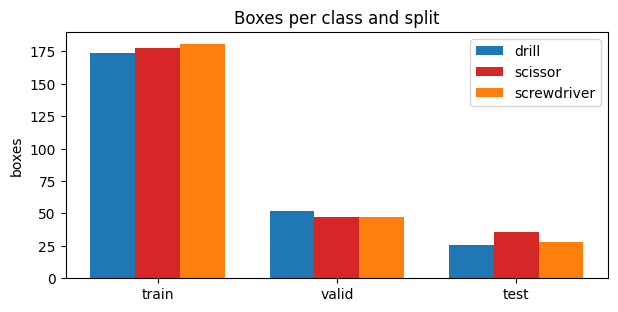

In [7]:
rows = read_manifest(DATASET)
table = split_summary(rows)
print(f"{'split':<7}{'images':>8}{'original':>10}{'public':>8}" + "".join(f"{name:>13}" for name in CLASSES))
for row in table:
    print(f"{row['split']:<7}{row['images']:>8}{row['original']:>10}{row['public']:>8}" + "".join(f"{row[n]:>13}" for n in CLASSES))
plot_class_balance(table)

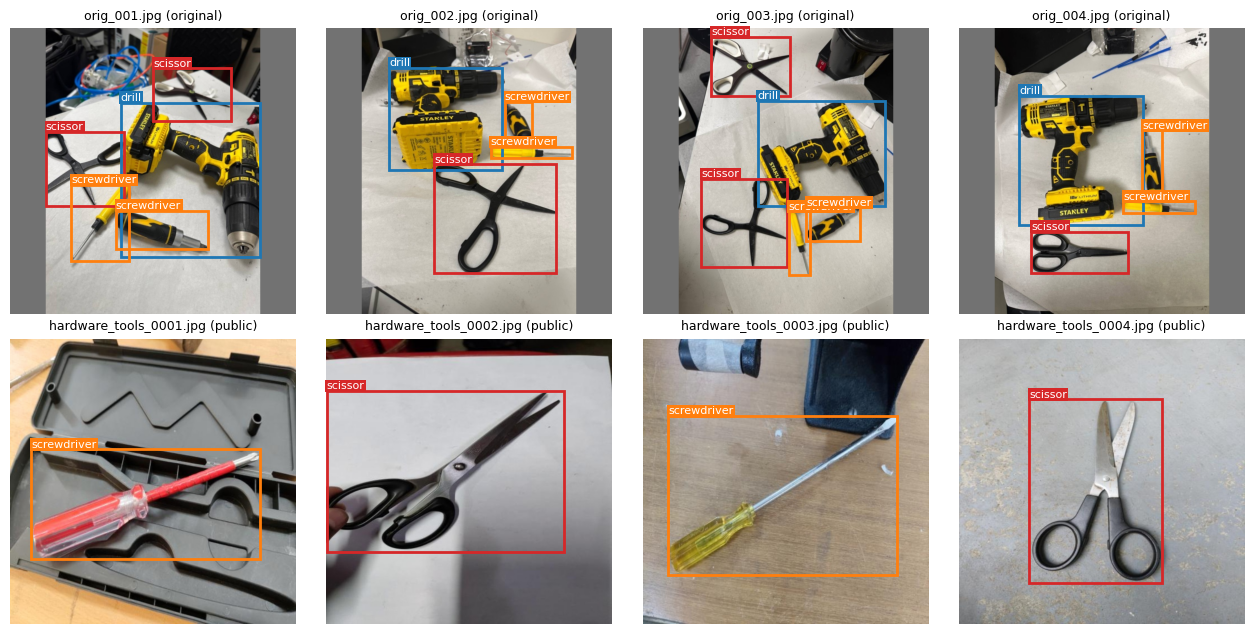

In [8]:
train_set = ToolDataset(DATASET, "train")
originals = [i for i, origin in enumerate(train_set.origins) if origin == "original"]
public = [i for i, origin in enumerate(train_set.origins) if origin == "public"]
show_samples(train_set, originals[:4] + public[:4])

## 3. Preprocessing and augmentation

**Letterboxing** scales the long side to 640 and pads with grey, so shapes are never distorted. The dataset was built
with exactly this rule; new photos (section 11) go through the same function.

In [9]:
# workbench_detection/data/transforms.py
def letterbox(image, size=IMAGE_SIZE, fill=LETTERBOX_FILL):
    """Return a padded RGB image and the transform needed to map boxes back to the original pixels."""
    width, height = image.size
    scale = min(size / width, size / height)
    resized_width = max(1, round(width * scale))
    resized_height = max(1, round(height * scale))
    left, top = (size - resized_width) // 2, (size - resized_height) // 2
    canvas = Image.new("RGB", (size, size), fill)
    canvas.paste(image.resize((resized_width, resized_height), Image.Resampling.BILINEAR), (left, top))
    transform = {"scale_x": resized_width / width, "scale_y": resized_height / height,
                 "left": left, "top": top, "width": width, "height": height}
    return canvas, transform


def restore_box(box, transform):
    """Map a 640-canvas xyxy box back to original-image pixels, clipping away the padding."""
    x1, y1, x2, y2 = box

    def restore_x(x):
        return max(0, min(transform["width"], (x - transform["left"]) / transform["scale_x"]))

    def restore_y(y):
        return max(0, min(transform["height"], (y - transform["top"]) / transform["scale_y"]))

    return [restore_x(x1), restore_y(y1), restore_x(x2), restore_y(y2)]

**Training augmentation** (training images only, a different draw every time an image is used): horizontal flip,
rotation within ±15°, shift and scale, brightness/contrast/gamma, hue/saturation, blur or sensor noise, a random grey
cutout, and for scissors a wider scale range and partial occlusion of the blades or handles. Every box must stay at
least 30% visible; otherwise the change is retried or skipped. **Mosaic** joins four training images into one.

In [10]:
# workbench_detection/data/augment.py
SCISSOR = 1                    # class ID; scissors get their own scale range and partial occlusion
MIN_VISIBLE = 0.3              # a box must stay at least 30% visible
MIN_SIDE = 4.0                 # and keep both sides at least 4 pixels
GEOMETRIC_TRIES = 5
MOSAIC_TRIES = 10
AUGMENTATION = {
    "horizontal_flip_p": 0.5,
    "rotate_deg": 15.0,
    "translate_fraction": 0.08,
    "scale_range": [0.8, 1.2],
    "brightness_contrast": 0.2,
    "gamma_range": [0.8, 1.25],
    "hue_shift_deg": 8,
    "saturation_range": [0.8, 1.2],
    "blur_p": 0.15,
    "noise_p": 0.15,
    "noise_sigma": 6.0,
    "cutout_p": 0.3,
    "cutout_fraction": 0.2,
    "scissor_scale_range": [0.7, 1.3],
    "scissor_occlusion_p": 0.5,
    "scissor_occlusion_area": [0.1, 0.3],
}


def _visible(boxes, reference_area, bounds=(0, 0, IMAGE_SIZE, IMAGE_SIZE)):
    """Return boxes clipped to bounds and a mask of those that stay usable."""
    clipped = boxes.copy()
    clipped[:, [0, 2]] = clipped[:, [0, 2]].clip(bounds[0], bounds[2])
    clipped[:, [1, 3]] = clipped[:, [1, 3]].clip(bounds[1], bounds[3])
    width, height = clipped[:, 2] - clipped[:, 0], clipped[:, 3] - clipped[:, 1]
    return clipped, (width >= MIN_SIDE) & (height >= MIN_SIDE) & (width * height >= MIN_VISIBLE * reference_area)


def _warp_boxes(boxes, matrix):
    """Apply an affine matrix to the four corners of each box and take their bounding box."""
    corners = np.ones((len(boxes), 4, 3))
    corners[:, 0, :2] = boxes[:, [0, 1]]
    corners[:, 1, :2] = boxes[:, [2, 1]]
    corners[:, 2, :2] = boxes[:, [2, 3]]
    corners[:, 3, :2] = boxes[:, [0, 3]]
    moved = corners @ matrix.T
    return np.concatenate([moved.min(axis=1), moved.max(axis=1)], axis=1)


def geometric(image, boxes, labels, rng):
    """Flip, then try up to 5 random rotation/scale/shift combinations that keep every box usable.

    If none works, only the flip is kept.
    """
    if rng.random() < AUGMENTATION["horizontal_flip_p"]:
        image = image[:, ::-1].copy()
        if len(boxes):
            boxes = boxes.copy()
            boxes[:, [0, 2]] = IMAGE_SIZE - boxes[:, [2, 0]]
    scale_range = AUGMENTATION["scissor_scale_range"] if (labels == SCISSOR).any() else AUGMENTATION["scale_range"]
    shift = AUGMENTATION["translate_fraction"] * IMAGE_SIZE
    for _ in range(GEOMETRIC_TRIES):
        matrix = cv2.getRotationMatrix2D((IMAGE_SIZE / 2, IMAGE_SIZE / 2),
                                         rng.uniform(-AUGMENTATION["rotate_deg"], AUGMENTATION["rotate_deg"]),
                                         rng.uniform(*scale_range))
        matrix[:, 2] += (rng.uniform(-shift, shift), rng.uniform(-shift, shift))
        if not len(boxes):
            return cv2.warpAffine(image, matrix, (IMAGE_SIZE, IMAGE_SIZE), flags=cv2.INTER_LINEAR,
                                  borderValue=LETTERBOX_FILL), boxes, labels
        moved = _warp_boxes(boxes, matrix)
        clipped, usable = _visible(moved, (moved[:, 2] - moved[:, 0]) * (moved[:, 3] - moved[:, 1]))
        if usable.all():
            return cv2.warpAffine(image, matrix, (IMAGE_SIZE, IMAGE_SIZE), flags=cv2.INTER_LINEAR,
                                  borderValue=LETTERBOX_FILL), clipped.astype(np.float32), labels
    return image, boxes, labels


def photometric(image, rng):
    """Brightness, contrast, gamma, hue, saturation, blur and sensor noise. Boxes do not move."""
    limit = AUGMENTATION["brightness_contrast"]
    output = image.astype(np.float32) * rng.uniform(1 - limit, 1 + limit) + 255 * rng.uniform(-limit, limit) / 2
    output = 255 * (output.clip(0, 255) / 255) ** rng.uniform(*AUGMENTATION["gamma_range"])
    hsv = cv2.cvtColor(output.astype(np.uint8), cv2.COLOR_RGB2HSV).astype(np.float32)
    hsv[..., 0] = (hsv[..., 0] + rng.uniform(-AUGMENTATION["hue_shift_deg"], AUGMENTATION["hue_shift_deg"]) / 2) % 180
    hsv[..., 1] = (hsv[..., 1] * rng.uniform(*AUGMENTATION["saturation_range"])).clip(0, 255)
    output = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)
    if rng.random() < AUGMENTATION["blur_p"]:
        output = cv2.GaussianBlur(output, (5, 5), 0)
    if rng.random() < AUGMENTATION["noise_p"]:
        noise = np.random.default_rng(rng.randrange(2**32)).normal(0, AUGMENTATION["noise_sigma"], output.shape)
        output = (output + noise).clip(0, 255).astype(np.uint8)
    return output


def _try_patch(image, hidden, boxes, x, y, w, h):
    """Grey out a rectangle unless the total hidden area of any box would pass the limit."""
    trial = hidden.copy()
    trial[y:y + h, x:x + w] = True
    for x1, y1, x2, y2 in boxes.astype(int):
        area = trial[y1:y2, x1:x2]
        if area.size and area.mean() > 1 - MIN_VISIBLE:
            return False
    hidden[y:y + h, x:x + w] = True
    image[y:y + h, x:x + w] = LETTERBOX_FILL[0]
    return True


def scissor_occlusion(image, hidden, boxes, labels, rng):
    """Partly cover one scissor box, since thin blades and handles are often occluded."""
    scissors = boxes[labels == SCISSOR]
    if not len(scissors) or rng.random() >= AUGMENTATION["scissor_occlusion_p"]:
        return
    x1, y1, x2, y2 = scissors[rng.randrange(len(scissors))]
    share = rng.uniform(*AUGMENTATION["scissor_occlusion_area"])
    w, h = max(int((x2 - x1) * share ** 0.5), 1), max(int((y2 - y1) * share ** 0.5), 1)
    x = int(rng.uniform(x1, max(x2 - w, x1)))
    y = int(rng.uniform(y1, max(y2 - h, y1)))
    _try_patch(image, hidden, boxes, x, y, min(w, IMAGE_SIZE - x), min(h, IMAGE_SIZE - y))


def cutout(image, hidden, boxes, rng):
    """A grey square at a random place, skipped if it would hide too much of a box."""
    if rng.random() >= AUGMENTATION["cutout_p"]:
        return
    side = int(IMAGE_SIZE * AUGMENTATION["cutout_fraction"] * rng.uniform(0.5, 1))
    _try_patch(image, hidden, boxes, rng.randrange(IMAGE_SIZE - side), rng.randrange(IMAGE_SIZE - side), side, side)


def augment(image, boxes, labels, rng):
    """The full training augmentation for one image."""
    image, boxes, labels = geometric(image, boxes, labels, rng)
    image = photometric(image, rng).copy()
    hidden = np.zeros((IMAGE_SIZE, IMAGE_SIZE), dtype=bool)
    scissor_occlusion(image, hidden, boxes, labels, rng)
    cutout(image, hidden, boxes, rng)
    return image, boxes, labels


def light_augment(image, boxes, labels, rng):
    """A lighter alternative: horizontal flip, brightness and contrast only."""
    photo = Image.fromarray(image)
    if rng.random() < 0.5:
        photo = ImageOps.mirror(photo)
        boxes = boxes.copy()
        boxes[:, [0, 2]] = image.shape[1] - boxes[:, [2, 0]]
    photo = ImageEnhance.Brightness(photo).enhance(rng.uniform(0.8, 1.2))
    photo = ImageEnhance.Contrast(photo).enhance(rng.uniform(0.8, 1.2))
    return np.asarray(photo), boxes, labels


AUGMENTATIONS = {"full": augment, "light": light_augment}


def mosaic(samples, rng):
    """Join four training images around a random centre; each quadrant keeps only boxes that stay usable."""
    cx, cy = rng.randint(IMAGE_SIZE // 4, 3 * IMAGE_SIZE // 4), rng.randint(IMAGE_SIZE // 4, 3 * IMAGE_SIZE // 4)
    canvas = np.full((IMAGE_SIZE, IMAGE_SIZE, 3), LETTERBOX_FILL[0], dtype=np.uint8)
    regions = [(0, 0, cx, cy), (cx, 0, IMAGE_SIZE, cy), (0, cy, cx, IMAGE_SIZE), (cx, cy, IMAGE_SIZE, IMAGE_SIZE)]
    all_boxes, all_labels = [np.zeros((0, 4), np.float32)], [np.zeros(0, np.int64)]
    for (x1, y1, x2, y2), (image, boxes, labels) in zip(regions, samples):
        width, height = x2 - x1, y2 - y1
        best = None
        # Choose the crop that leaves the fewest cut-off remnants without a label.
        for _ in range(MOSAIC_TRIES):
            offset_x, offset_y = rng.randint(0, IMAGE_SIZE - width), rng.randint(0, IMAGE_SIZE - height)
            moved = boxes.copy()
            moved[:, [0, 2]] += x1 - offset_x
            moved[:, [1, 3]] += y1 - offset_y
            clipped, usable = _visible(moved, (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1]), (x1, y1, x2, y2))
            touching = (moved[:, 2] > x1) & (moved[:, 0] < x2) & (moved[:, 3] > y1) & (moved[:, 1] < y2)
            remnants = int((touching & ~usable).sum())
            score = (remnants, -int(usable.sum()))
            if best is None or score < best[0]:
                best = (score, offset_x, offset_y, clipped[usable], labels[usable])
        _, offset_x, offset_y, kept, kept_labels = best
        canvas[y1:y2, x1:x2] = image[offset_y:offset_y + height, offset_x:offset_x + width]
        all_boxes.append(kept.astype(np.float32))
        all_labels.append(kept_labels)
    return canvas, np.concatenate(all_boxes), np.concatenate(all_labels)

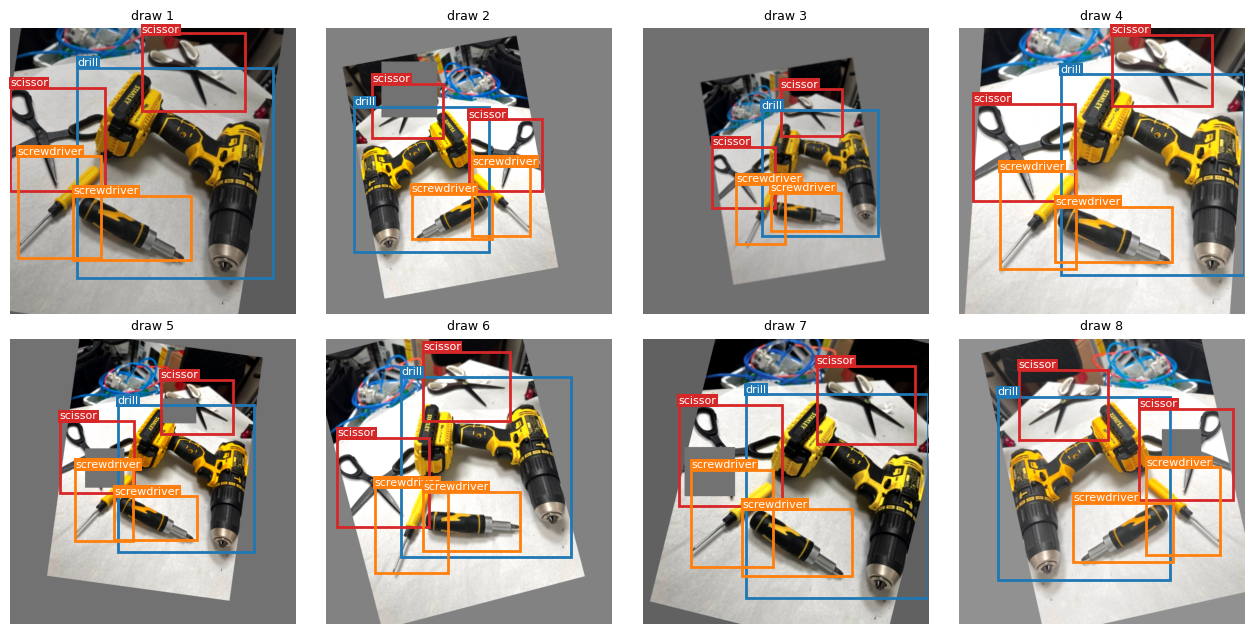

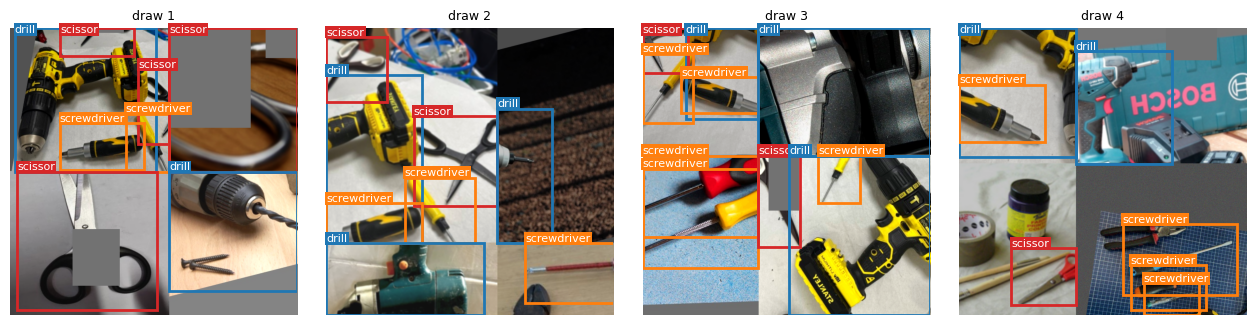

In [11]:
scissor_image = next(i for i, labels in enumerate(train_set.labels) if 1 in labels)
show_augmentations(ToolDataset(DATASET, "train", augment=True, augmentation=CONFIG.augmentation), scissor_image)
show_augmentations(ToolDataset(DATASET, "train", augment=True, mosaic_p=1.0, augmentation=CONFIG.augmentation), 0, count=4)

**Class-aware sampling.** Each training image is drawn with a weight that boosts the rarest class it contains
(inverse box frequency, capped at 2×), so every class appears about equally often per epoch. `original_weight`
can additionally favour the group's own photos if they score lower on validation.

In [12]:
# workbench_detection/data/sampling.py
MAX_CLASS_WEIGHT = 2.0  # minority classes are upweighted by at most 2x


def image_weights(dataset, original_weight=1.0):
    """Per-image sampling weights computed from training boxes only.

    Original photos are weighted first; class weights are then the inverse box frequency under those
    weights, capped at 2x, and each image takes the weight of its rarest class.
    """
    if dataset.split not in TRAINING_SPLITS:
        raise ValueError("Sampling weights are computed from training data only.")
    base = [original_weight if origin == "original" else 1.0 for origin in dataset.origins]
    counts = np.zeros(len(CLASSES))
    for weight, labels in zip(base, dataset.labels):
        counts += weight * np.bincount(labels, minlength=len(CLASSES))
    class_weight = np.minimum(counts.max() / counts, MAX_CLASS_WEIGHT)
    return [weight * (float(class_weight[labels].max()) if len(labels) else 1.0)
            for weight, labels in zip(base, dataset.labels)]


def expected_box_counts(dataset, weights):
    """Boxes per class one epoch is expected to contain under the given weights."""
    scale = len(weights) / sum(weights)
    counts = np.zeros(len(CLASSES))
    for weight, labels in zip(weights, dataset.labels):
        counts += scale * weight * np.bincount(labels, minlength=len(CLASSES))
    return counts


def make_train_sampler(dataset, original_weight=1.0, generator=None):
    weights = image_weights(dataset, original_weight)
    dataset.sample_weights = weights
    return WeightedRandomSampler(weights, num_samples=len(dataset), replacement=True, generator=generator)

Expected boxes per epoch: {'drill': '174 -> 177', 'scissor': '178 -> 177', 'screwdriver': '181 -> 181'}


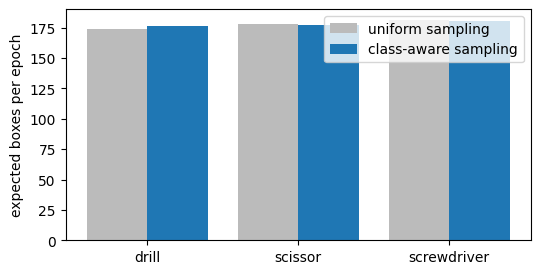

In [13]:
weights = image_weights(train_set, CONFIG.original_weight)
uniform, balanced = expected_box_counts(train_set, [1.0] * len(train_set)), expected_box_counts(train_set, weights)
print("Expected boxes per epoch:", {n: f"{u:.0f} -> {b:.0f}" for n, u, b in zip(CLASSES, uniform, balanced)})
plot_box_counts(uniform, balanced)

## 4. Model

Box utilities first: format conversion, IoU and non-maximum suppression, used by the model, the loss and the evaluator.

In [14]:
# workbench_detection/boxes.py
def xywh_to_xyxy(boxes):
    """Centre-format boxes (..., 4) to corner format."""
    return torch.cat((boxes[..., :2] - boxes[..., 2:] / 2, boxes[..., :2] + boxes[..., 2:] / 2), -1)


def pixels_to_cxcywh(boxes):
    """Pixel xyxy boxes on the 640 canvas to normalized centre format, the YOLO target encoding."""
    return torch.stack([(boxes[:, 0] + boxes[:, 2]) / 2, (boxes[:, 1] + boxes[:, 3]) / 2,
                        boxes[:, 2] - boxes[:, 0], boxes[:, 3] - boxes[:, 1]], dim=1) / IMAGE_SIZE


def box_iou(a, b):
    """Pairwise IoU between xyxy tensors a (N, 4) and b (M, 4) -> (N, M)."""
    inter = (torch.minimum(a[:, None, 2:], b[None, :, 2:]) - torch.maximum(a[:, None, :2], b[None, :, :2])).clamp(min=0).prod(-1)
    area_a = (a[:, 2:] - a[:, :2]).clamp(min=0).prod(-1)
    area_b = (b[:, 2:] - b[:, :2]).clamp(min=0).prod(-1)
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)


def wh_iou(a, b):
    """IoU of width/height pairs aligned at a common centre: (N, 2) x (M, 2) -> (N, M). Used for anchors."""
    inter = torch.minimum(a[:, None], b[None]).prod(-1)
    return inter / (a.prod(-1)[:, None] + b.prod(-1)[None] - inter + 1e-9)


def pair_iou(box_a, box_b):
    """IoU of two pixel xyxy boxes given as plain sequences (exact float arithmetic, for scoring)."""
    intersection = max(0.0, min(box_a[2], box_b[2]) - max(box_a[0], box_b[0])) * max(
        0.0, min(box_a[3], box_b[3]) - max(box_a[1], box_b[1]))
    area_a = (box_a[2] - box_a[0]) * (box_a[3] - box_a[1])
    area_b = (box_b[2] - box_b[0]) * (box_b[3] - box_b[1])
    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0


def nms(boxes, scores, threshold=0.5):
    """Greedy non-maximum suppression: keep the highest score, drop boxes overlapping it by more than threshold."""
    order = scores.argsort(descending=True)
    keep = []
    while len(order):
        best = order[0]
        keep.append(best)
        if len(order) == 1:
            break
        rest = order[1:]
        order = rest[box_iou(boxes[best:best + 1], boxes[rest])[0] <= threshold]
    return torch.stack(keep) if keep else torch.empty(0, dtype=torch.long, device=boxes.device)

**Architecture.** A ResNet-18 backbone (7×7 stem, four stages of basic residual blocks) produces stride-16 and
stride-32 features. The YOLOv2 head adds two 3×3 convolutions on the deep features, reorganizes the stride-16
features onto the 20 × 20 grid (passthrough layer) and concatenates both, then predicts for each of the 5 anchors in
every cell: x, y, w, h offsets, objectness and 3 class scores (5 × 8 = 40 output channels). With `CONFIG.stride = 16`
the deep features are upsampled onto the 40 × 40 grid of the stride-16 features instead, giving small objects such
as screwdrivers cells of their own.

In [15]:
# workbench_detection/models/yolov2.py
def conv_bn(cin, cout, k=3, stride=1):
    """Convolution, batch norm and leaky ReLU: the building block of the YOLOv2 layers."""
    return nn.Sequential(nn.Conv2d(cin, cout, k, stride, k // 2, bias=False), nn.BatchNorm2d(cout),
                         nn.LeakyReLU(.1, inplace=True))


class BasicBlock(nn.Module):
    """ResNet basic block: two 3x3 convolutions with a skip connection (1x1 projection when shapes change)."""

    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False)
        self.b1 = nn.BatchNorm2d(cout)
        self.c2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False)
        self.b2 = nn.BatchNorm2d(cout)
        self.skip = (nn.Identity() if cin == cout and stride == 1 else
                     nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout)))

    def forward(self, x):
        return F.relu(self.b2(self.c2(F.relu(self.b1(self.c1(x))))) + self.skip(x))


class YOLOv2ResNet18(nn.Module):
    """ResNet-18 stages (stem, s1-s4) feed the YOLOv2 head.

    Stride 32 (YOLOv2): the passthrough layer reorganizes the stride-16 features of s3 onto the 20 x 20 grid
    (pixel_unshuffle) and concatenates them with the deep features, keeping finer detail for small tools.
    Stride 16: the deep features are upsampled onto the 40 x 40 grid of s3 instead, so objects smaller than a
    32-pixel cell get cells of their own. Both feed the same 1280-channel head; it is still one output scale.
    """

    def __init__(self, anchors, classes=len(CLASSES), stride=32):
        super().__init__()
        if stride not in (16, 32):
            raise ValueError("stride must be 16 or 32")
        self.register_buffer("anchors", anchors.clone().float())  # (A, 2) normalized width, height
        self.classes, self.stride = classes, stride
        self.stem = nn.Sequential(nn.Conv2d(3, 64, 7, 2, 3, bias=False), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(3, 2, 1))
        self.s1 = nn.Sequential(BasicBlock(64, 64), BasicBlock(64, 64))
        self.s2 = nn.Sequential(BasicBlock(64, 128, 2), BasicBlock(128, 128))
        self.s3 = nn.Sequential(BasicBlock(128, 256, 2), BasicBlock(256, 256))
        self.s4 = nn.Sequential(BasicBlock(256, 512, 2), BasicBlock(512, 512))
        self.deep = nn.Sequential(conv_bn(512, 1024), conv_bn(1024, 1024))
        self.passthrough = conv_bn(256, 64 if stride == 32 else 256, 1)
        self.head = nn.Sequential(conv_bn(1280, 1024), nn.Conv2d(1024, len(anchors) * (5 + classes), 1))

    def forward(self, x):
        fine = self.s3(self.s2(self.s1(self.stem(x))))                  # stride 16, 256 channels
        deep = self.deep(self.s4(fine))                                   # stride 32, 1024 channels
        if self.stride == 32:
            route = F.pixel_unshuffle(self.passthrough(fine), 2)          # stride 32, 256 channels
        else:
            deep = F.interpolate(deep, scale_factor=2, mode="nearest")    # stride 16, 1024 channels
            route = self.passthrough(fine)                                # stride 16, 256 channels
        raw = self.head(torch.cat((deep, route), 1))
        b, _, h, w = raw.shape
        return raw.view(b, len(self.anchors), 5 + self.classes, h, w).permute(0, 1, 3, 4, 2).contiguous()

**Initialization.** The backbone starts from ImageNet weights, copied by name into the hand-built layers; the YOLOv2
layers start random. The last layer's objectness bias starts at 1% instead of 50%: with about 1.5 objects but 2000
anchors per image, a 50% start makes background errors dominate the first updates (measured below).

In [16]:
# workbench_detection/models/yolov2.py
def load_imagenet_backbone(model):
    """Copy ImageNet ResNet-18 weights (torchvision) into the hand-built backbone: stem and s1-s4.

    Only the backbone starts from ImageNet; the YOLOv2 layers (deep, passthrough, head) stay random.
    The layers mirror torchvision's ResNet-18, so the weights map by name and shape.
    """
    from torchvision.models import ResNet18_Weights, resnet18

    source = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1).state_dict()
    target = model.state_dict()
    mapped = {}
    for key, value in source.items():
        if key.startswith("fc."):  # the ImageNet classifier is not part of the backbone
            continue
        if key.startswith("conv1."):
            name = "stem.0." + key.removeprefix("conv1.")
        elif key.startswith("bn1."):
            name = "stem.1." + key.removeprefix("bn1.")
        else:  # layer1.0.conv1.weight -> s1.0.c1.weight
            name = "s" + key.removeprefix("layer")
            for old, new in ((".conv1.", ".c1."), (".bn1.", ".b1."), (".conv2.", ".c2."),
                             (".bn2.", ".b2."), (".downsample.", ".skip.")):
                name = name.replace(old, new)
        if name not in target or target[name].shape != value.shape:
            raise ValueError(f"ImageNet weight {key} does not match backbone layer {name}.")
        mapped[name] = value
    model.load_state_dict(mapped, strict=False)
    return len(mapped)


OBJECTNESS_PRIOR = 0.01


def init_objectness_prior(model, prior=OBJECTNESS_PRIOR):
    """Start every anchor's objectness at `prior` instead of 0.5.

    With about 1.5 objects per image and 2000 anchors, a 0.5 start makes the background term about 89%
    of the initial loss and destabilizes the first epochs.
    """
    head = model.head[-1]
    with torch.no_grad():
        head.bias.view(len(model.anchors), 5 + model.classes)[:, 4] = math.log(prior / (1 - prior))

**Anchors** are the typical box shapes, found by k-means on the training boxes with 1 − IoU as the distance
(YOLOv2's dimension clusters). Each prediction is an offset from one of them. YOLOv2 uses 5 (`CONFIG.anchors`);
more anchors give small, thin screwdrivers shapes of their own.

In [17]:
# workbench_detection/models/yolov2.py
def cluster_anchors(wh, k=5, seed=SEED):
    """k-means on box width/height with 1 - IoU as the distance and medians as centres (YOLOv2's priors).

    wh: (N, 2) normalized training box sizes. Returns k anchors sorted by area.
    """
    if len(wh) < k:
        raise ValueError("Not enough training boxes to cluster anchors")
    generator = torch.Generator().manual_seed(seed)
    centers = wh[torch.randperm(len(wh), generator=generator)[:k]].clone()
    for _ in range(100):
        assign = wh_iou(wh, centers).argmax(1)
        updated = torch.stack([wh[assign == j].median(0).values if (assign == j).any() else centers[j]
                               for j in range(k)])
        if torch.allclose(updated, centers, atol=1e-6):
            break
        centers = updated
    return centers[centers.prod(1).argsort()].clamp(min=1 / IMAGE_SIZE)


def anchors_from_dataset(dataset, k=5):
    """k anchors from the training split's boxes only (validation and test never influence them)."""
    sizes = torch.from_numpy(np.concatenate([boxes[:, 2:] - boxes[:, :2] for boxes in dataset.boxes]))
    return cluster_anchors(sizes / IMAGE_SIZE, k)

In [18]:
# workbench_detection/visualize.py — figures
def plot_anchors(dataset, anchors):
    """Training box sizes with the k-means anchor shapes on top."""
    import matplotlib.pyplot as plt

    sizes = np.concatenate([boxes[:, 2:] - boxes[:, :2] for boxes in dataset.boxes]) / IMAGE_SIZE
    labels = np.concatenate(dataset.labels)
    figure, axis = plt.subplots(figsize=(5.5, 4.5))
    for class_id, name in enumerate(CLASSES):
        chosen = labels == class_id
        axis.scatter(sizes[chosen, 0], sizes[chosen, 1], s=10, alpha=0.5, color=CLASS_COLOURS[name], label=name)
    anchors = np.asarray(anchors)
    axis.scatter(anchors[:, 0], anchors[:, 1], s=180, marker="X", color="black", label="anchors")
    axis.set_xlabel("box width (fraction of image)")
    axis.set_ylabel("box height (fraction of image)")
    axis.set_title("Training box sizes and the 5 anchors")
    axis.legend()
    plt.show()


def show_assignment(dataset, index, anchors, grid=IMAGE_SIZE // 32):
    """Each object's responsible grid cell and the anchor shape assigned to it (best width/height IoU)."""
    import matplotlib.pyplot as plt
    import torch
    from matplotlib.patches import Rectangle


    image, boxes, labels = dataset.raw(index)
    figure, axis = plt.subplots(figsize=(5.5, 5.5))
    draw_boxes(axis, image, boxes, labels, colour=TRUTH_COLOUR, title="green: object | dashed: responsible cell and anchor")
    cell = IMAGE_SIZE / grid
    for x in range(grid + 1):
        axis.axvline(x * cell, color="white", linewidth=0.3)
        axis.axhline(x * cell, color="white", linewidth=0.3)
    for box in boxes:
        cx, cy = (box[0] + box[2]) / 2, (box[1] + box[3]) / 2
        size = torch.tensor([[(box[2] - box[0]) / IMAGE_SIZE, (box[3] - box[1]) / IMAGE_SIZE]])
        slot = int(wh_iou(size, torch.as_tensor(anchors)).argmax())
        aw, ah = float(anchors[slot][0]) * IMAGE_SIZE, float(anchors[slot][1]) * IMAGE_SIZE
        ix, iy = int(cx // cell), int(cy // cell)
        axis.add_patch(Rectangle((ix * cell, iy * cell), cell, cell, color="yellow", alpha=0.6))
        axis.add_patch(Rectangle((cx - aw / 2, cy - ah / 2), aw, ah, fill=False, edgecolor="yellow",
                                 linestyle="--", linewidth=1.5))
        axis.text(cx, cy, f"anchor {slot}", color="black", fontsize=8, ha="center",
                  bbox=dict(facecolor="yellow", pad=1, linewidth=0))
    plt.show()

Anchors (width, height as fractions of the image): [(0.149, 0.047), (0.07, 0.148), (0.169, 0.259), (0.325, 0.141), (0.119, 0.715), (0.305, 0.482), (0.455, 0.341), (0.554, 0.617), (0.833, 0.493)]


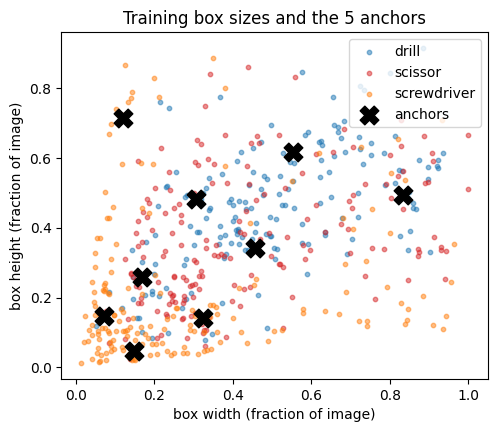

backbone (stem, s1-s4): 11,176,512 parameters
YOLOv2 layers (deep, passthrough, head): 26,098,248 parameters
Output shape for one image: (1, 9, 40, 40, 8) = (batch, anchors, grid y, grid x, 5 + classes)


In [19]:
anchors = anchors_from_dataset(train_set, CONFIG.anchors)
print("Anchors (width, height as fractions of the image):", [tuple(round(float(v), 3) for v in a) for a in anchors])
plot_anchors(train_set, anchors)
model = YOLOv2ResNet18(anchors, stride=CONFIG.stride)
parts = {"backbone (stem, s1-s4)": [model.stem, model.s1, model.s2, model.s3, model.s4],
         "YOLOv2 layers (deep, passthrough, head)": [model.deep, model.passthrough, model.head]}
for name, modules in parts.items():
    print(f"{name}: {sum(p.numel() for m in modules for p in m.parameters()):,} parameters")
with torch.no_grad():
    print("Output shape for one image:", tuple(model(train_set[0][0][None]).shape), "= (batch, anchors, grid y, grid x, 5 + classes)")

## 5. Loss and decoding

**Decoding** turns offsets into boxes: centre = cell index + sigmoid offset; size = anchor × exp(offset). Scores are
objectness × class probability; detections above a confidence threshold go through class-wise NMS.

In [20]:
# workbench_detection/models/yolov2.py
def decode(raw, anchors):
    """Raw offsets -> normalized centre-format boxes (B, A, H, W, 4).

    x, y: sigmoid offset within the grid cell plus the cell index; w, h: anchor size times exp(offset).
    """
    _, a, h, w, _ = raw.shape
    gy, gx = torch.meshgrid(torch.arange(h, device=raw.device), torch.arange(w, device=raw.device), indexing="ij")
    grid = torch.stack((gx, gy), -1).to(raw.dtype)
    xy = (raw[..., :2].sigmoid() + grid) / raw.new_tensor([w, h])
    wh = raw[..., 2:4].clamp(-8, 8).exp() * anchors[None, :, None, None, :]
    return torch.cat((xy, wh), -1)


def postprocess(raw, anchors, conf=.05, nms_iou=.5, topk=300):
    """Decode, filter by confidence and apply class-wise NMS. Returns normalized xyxy boxes per image.

    Score = objectness x class probability. At most 1000 candidates enter NMS and topk boxes are kept.
    """
    boxes = xywh_to_xyxy(decode(raw, anchors)).clamp(0, 1)
    results = []
    probs = raw[..., 4:5].sigmoid() * raw[..., 5:].softmax(-1)
    for b in range(len(raw)):
        flat = boxes[b].reshape(-1, 4)
        scores, classes = probs[b].reshape(-1, len(CLASSES)).max(1)
        ok = (scores >= conf) & ((flat[:, 2:] - flat[:, :2]).min(1).values > 0)
        flat, scores, classes = flat[ok], scores[ok], classes[ok]
        idx = scores.argsort(descending=True)[:1000]
        flat, scores, classes = flat[idx], scores[idx], classes[idx]
        chosen = []
        for c in range(len(CLASSES)):
            idx = torch.where(classes == c)[0]
            chosen.extend(idx[nms(flat[idx], scores[idx], nms_iou)].tolist())
        idx = torch.tensor(chosen, device=raw.device, dtype=torch.long)
        idx = idx[scores[idx].argsort(descending=True)[:topk]]
        results.append({"boxes": flat[idx].detach().cpu(), "scores": scores[idx].detach().cpu(),
                        "labels": classes[idx].detach().cpu()})
    return results

**Loss.** Each object is assigned to the grid cell containing its centre and to the best-matching free anchor there.
Four terms: location (box offsets), object (objectness of assigned anchors, target = IoU of their predicted box),
background (objectness of all other anchors) and class (cross-entropy). Because small boxes naturally reach lower
IoUs, the IoU target pushes small objects towards low confidence; `objectness_target="one"` uses 1 instead.

In [21]:
# workbench_detection/models/loss.py
LOCATION_WEIGHT = 5.0     # box centre and size
OBJECT_WEIGHT = 5.0       # objectness of anchors responsible for an object (raised from 1 in round 2.2)
BACKGROUND_WEIGHT = 0.5   # objectness of anchors with no object
IGNORE_IOU = 0.6          # background anchors whose prediction already overlaps an object this much are not penalized


def encode_targets(targets):
    """Dataset targets (pixel xyxy) -> per-image tensors of [class, cx, cy, w, h], normalized."""
    return [torch.cat((row["labels"].float()[:, None], pixels_to_cxcywh(row["boxes"])), dim=1) for row in targets]


def yolo_loss(raw, targets, anchors, ignore_iou=IGNORE_IOU, objectness_target="iou", anchors_per_object=1):
    """YOLOv2 loss for raw predictions (B, A, H, W, 5 + C) and encoded targets.

    Assignment: each object goes to the grid cell containing its centre and to the free anchor whose
    shape best matches it (larger objects choose first). With anchors_per_object=k, the k best-matching free
    anchors in that cell all learn the object, so thin objects that fit no single anchor well get more
    positive examples; NMS removes the duplicate boxes at inference. Terms, summed then divided by the batch size:
      location   BCE on the x, y offsets within the cell + MSE on log(w, h / anchor)
      object     MSE between the objectness of assigned anchors and their predicted box's IoU
                 (objectness_target="one": and 1, so small objects, whose IoU is naturally lower,
                 are not pushed towards low confidence)
      background squared objectness of unassigned anchors (except ignored ones)
      class      cross-entropy on assigned anchors
    """
    b, a, h, w, _ = raw.shape
    pos = torch.zeros(raw.shape[:-1], device=raw.device, dtype=torch.bool)
    target = torch.zeros_like(raw)
    assigned_boxes = torch.zeros_like(raw[..., :4])
    collisions = 0
    for bi, gt in enumerate(targets):
        for row in gt[torch.argsort(gt[:, 3] * gt[:, 4], descending=True)]:
            cls, x, y, bw, bh = row.tolist()
            ix, iy = min(int(x * w), w - 1), min(int(y * h), h - 1)
            ranking = wh_iou(row[None, 3:5].to(raw.device), anchors).argsort(1, descending=True)[0]
            slots = [int(j) for j in ranking if not pos[bi, j, iy, ix]][:anchors_per_object]
            if not slots:  # every anchor in this cell is already taken
                collisions += 1
                continue
            for slot in slots:
                pos[bi, slot, iy, ix] = True
                target[bi, slot, iy, ix, :2] = raw.new_tensor([x * w - ix, y * h - iy])
                target[bi, slot, iy, ix, 2:4] = torch.log(row[3:5].to(raw.device) / anchors[slot] + 1e-9)
                target[bi, slot, iy, ix, 5] = cls
                assigned_boxes[bi, slot, iy, ix] = row[1:5].to(raw.device)
    predicted = decode(raw, anchors)
    negative = ~pos
    with torch.no_grad():
        for bi, gt in enumerate(targets):
            if len(gt):
                overlap = box_iou(xywh_to_xyxy(predicted[bi].reshape(-1, 4)),
                                  xywh_to_xyxy(gt[:, 1:5].to(raw.device))).max(1).values
                negative[bi] &= overlap.reshape(a, h, w) < ignore_iou
    zero = raw.sum() * 0
    if pos.any():
        location = (F.binary_cross_entropy_with_logits(raw[..., :2][pos], target[..., :2][pos], reduction="sum")
                    + F.mse_loss(raw[..., 2:4][pos], target[..., 2:4][pos], reduction="sum"))
        pp, tt = xywh_to_xyxy(predicted[pos]), xywh_to_xyxy(assigned_boxes[pos])
        inter = (torch.minimum(pp[:, 2:], tt[:, 2:]) - torch.maximum(pp[:, :2], tt[:, :2])).clamp(min=0).prod(1)
        iou = (inter / ((pp[:, 2:] - pp[:, :2]).prod(1) + (tt[:, 2:] - tt[:, :2]).prod(1) - inter + 1e-9)).detach()
        goal = iou if objectness_target == "iou" else torch.ones_like(iou)
        objectness = F.mse_loss(raw[..., 4][pos].sigmoid(), goal, reduction="sum")
        classification = F.cross_entropy(raw[..., 5:][pos], target[..., 5][pos].long(), reduction="sum")
    else:
        location = objectness = classification = zero
    background = raw[..., 4][negative].sigmoid().square().sum()
    loss = (LOCATION_WEIGHT * location + OBJECT_WEIGHT * objectness + BACKGROUND_WEIGHT * background
            + classification) / b
    details = {"loss": float(loss.detach()), "assigned": int(pos.sum()), "collisions": collisions,
               "location": float(LOCATION_WEIGHT * location.detach() / b),
               "object": float(OBJECT_WEIGHT * objectness.detach() / b),
               "background": float(BACKGROUND_WEIGHT * background.detach() / b),
               "class": float(classification.detach() / b)}
    return loss, details


def yolo_loss_on_cpu(raw, targets, anchors, objectness_target="iou", anchors_per_object=1):
    """yolo_loss with the target assignment on the CPU; the result returns to raw's device.

    The assignment loops object by object, and on a GPU every step would wait for the device. Moving the
    small raw tensor is cheap, gradients still flow back to the model, and the value is unchanged.
    """
    loss, details = yolo_loss(raw.float().cpu(), encode_targets(targets), anchors.cpu(),
                              objectness_target=objectness_target, anchors_per_object=anchors_per_object)
    return loss.to(raw.device), details

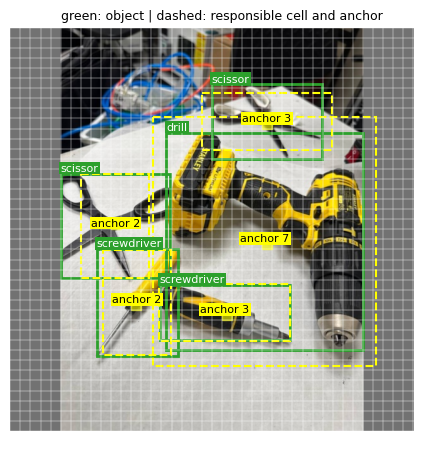

objectness prior off: loss 2006.0 | background term 94% | 66 assigned anchors out of 115200
objectness prior on : loss 124.4 | background term 1% | 66 assigned anchors out of 115200


In [22]:
show_assignment(train_set, scissor_image, anchors, grid=IMAGE_SIZE // CONFIG.stride)
images, batch_targets = collate([train_set[i] for i in range(8)])
for prior in (False, True):
    seed_everything()
    untrained = YOLOv2ResNet18(anchors, stride=CONFIG.stride)
    if prior:
        init_objectness_prior(untrained)
    with torch.no_grad():
        raw = untrained(images)
        _, terms = yolo_loss(raw, encode_targets(batch_targets), untrained.anchors, objectness_target=CONFIG.objectness_target,
                             anchors_per_object=CONFIG.anchors_per_object)
    share = terms["background"] / terms["loss"]
    print(f"objectness prior {'on ' if prior else 'off'}: loss {terms['loss']:.1f} | background term {share:.0%} | "
          f"{terms['assigned']} assigned anchors out of {raw[..., 0].numel()}")

## 6. Evaluation

Predictions and ground truth are checked strictly (every image needs a record; boxes inside the canvas; scores in
[0, 1]) so nothing is silently dropped. The ground-truth loader cross-checks the COCO and YOLO labels of every image.

In [23]:
# workbench_detection/evaluation/records.py
def finite_number(value: Any) -> bool:
    return isinstance(value, (float, int)) and not isinstance(value, bool) and math.isfinite(value)


def mean_or_none(values: Sequence[float]) -> float | None:
    return statistics.mean(values) if values else None


def ratio(numerator: int | float, denominator: int | float) -> float:
    # Explicit zero-denominator convention for P/R/F1. AP has separate null handling.
    return numerator / denominator if denominator else 0.0


def save_json(path: str | Path, value: Any) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n", encoding="utf-8")


def load_json(path: str | Path) -> dict:
    with Path(path).open(encoding="utf-8-sig") as stream:
        result = json.load(stream)
    if not isinstance(result, dict):
        raise ValueError(f"{path}: JSON root must be an object.")
    return result


def write_csv(path: str | Path, rows: list[dict], fields: Sequence[str]) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", newline="", encoding="utf-8-sig") as stream:
        writer = csv.DictWriter(stream, fieldnames=fields, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(rows)


def validate_ground_truth(data: dict) -> dict[str, dict]:
    """Reject malformed data rather than silently dropping images or labels."""
    if data.get("data_kind") not in ("real", "synthetic"):
        raise ValueError("Ground truth must declare data_kind='real' or 'synthetic'.")
    classes = data.get("classes")
    if (not isinstance(classes, list) or not classes
            or any(not isinstance(c, str) or not c.strip() for c in classes)
            or len(set(classes)) != len(classes)):
        raise ValueError("classes must be a nonempty list of unique nonempty strings.")
    images = data.get("images")
    if not isinstance(images, list) or not images:
        raise ValueError("Ground truth images must be a nonempty list.")
    indexed = {}
    for record in images:
        if not isinstance(record, dict):
            raise ValueError("Each ground-truth image must be an object.")
        image_id = record.get("image_id")
        if not isinstance(image_id, str) or not image_id or image_id in indexed:
            raise ValueError("Ground-truth image_id values must be unique nonempty strings.")
        for key in ("width", "height"):
            if not finite_number(record.get(key)) or record[key] <= 0:
                raise ValueError(f"{image_id}: {key} must be positive and finite.")
        if "source" in record and (not isinstance(record["source"], str) or not record["source"]):
            raise ValueError(f"{image_id}: source must be a nonempty string.")
        tags = record.get("tags", [])
        if not isinstance(tags, list) or any(not isinstance(t, str) or not t for t in tags):
            raise ValueError(f"{image_id}: tags must be a list of nonempty strings.")
        _validate_instances(record, record, len(classes), prediction=False)
        indexed[image_id] = record
    return indexed


def _validate_instances(record: dict, image: dict, class_count: int, prediction: bool) -> None:
    image_id = record["image_id"]
    boxes, labels = record.get("boxes"), record.get("labels")
    if not isinstance(boxes, list) or not isinstance(labels, list) or len(boxes) != len(labels):
        raise ValueError(f"{image_id}: boxes and labels must be equal-length lists.")
    for box in boxes:
        if not isinstance(box, list) or len(box) != 4 or not all(finite_number(x) for x in box):
            raise ValueError(f"{image_id}: every box must contain four finite numbers.")
        x1, y1, x2, y2 = box
        if not (0 <= x1 < x2 <= image["width"] and 0 <= y1 < y2 <= image["height"]):
            raise ValueError(f"{image_id}: invalid/out-of-bounds xyxy box {box}.")
    if any(not isinstance(label, int) or isinstance(label, bool)
           or not 0 <= label < class_count for label in labels):
        raise ValueError(f"{image_id}: labels must be integers in [0, {class_count - 1}].")
    if prediction:
        scores = record.get("scores")
        if (not isinstance(scores, list) or len(scores) != len(boxes)
                or any(not finite_number(s) or not 0 <= s <= 1 for s in scores)):
            raise ValueError(f"{image_id}: scores must match boxes and lie in [0, 1].")


def validate_predictions(data: dict, ground_truth: dict) -> dict[str, dict]:
    gt = validate_ground_truth(ground_truth)
    if data.get("data_kind") != ground_truth["data_kind"]:
        raise ValueError("Prediction and ground-truth data_kind must agree.")
    if "classes" in data and data["classes"] != ground_truth["classes"]:
        raise ValueError("Prediction class order differs from ground truth.")
    if not isinstance(data.get("model_name"), str) or not data["model_name"].strip():
        raise ValueError("Prediction JSON must declare a nonempty model_name.")
    if not isinstance(data.get("metadata", {}), dict):
        raise ValueError("Prediction metadata must be an object.")
    if not isinstance(data.get("images"), list):
        raise ValueError("Prediction images must be a list.")
    indexed = {}
    for record in data["images"]:
        if not isinstance(record, dict):
            raise ValueError("Each prediction image must be an object.")
        image_id = record.get("image_id")
        if not isinstance(image_id, str) or image_id not in gt or image_id in indexed:
            raise ValueError(f"Unknown or duplicate prediction image_id: {image_id!r}.")
        _validate_instances(record, gt[image_id], len(ground_truth["classes"]), prediction=True)
        indexed[image_id] = record
    missing = set(gt) - set(indexed)
    if missing:
        raise ValueError(f"Missing predictions for {sorted(missing)}. Supply explicit empty lists for no detections.")
    return indexed


def _canvas_box(box: list[float], name: str, clips: list[dict]) -> list[float]:
    """Clip only <=0.001 pixel export rounding; keep core validation strict."""
    if len(box) != 4 or not all(finite_number(v) for v in box):
        raise ValueError(f"{name}: box must have four finite coordinates.")
    outside = max(0.0, -min(box), max(box) - 640)
    if outside > 0.001:
        raise ValueError(f"{name}: box outside 640x640 by {outside:g} pixels.")
    clipped = [min(640.0, max(0.0, v)) for v in box]
    if clipped != box:
        clips.append({"file_name": name, "before": box, "after": clipped})
    if clipped[0] >= clipped[2] or clipped[1] >= clipped[3]:
        raise ValueError(f"{name}: box has nonpositive area.")
    return clipped


def load_ground_truth(dataset_root: str | Path, split: str = "valid", *,
                              annotation_format: str = "coco", allow_test: bool = False) -> dict:
    """Load one split's ground truth from the dataset folder, cross-checking COCO and YOLO labels.

    COCO and YOLO are cross-checked on EVERY imported image (0.001 px tolerance).
    Default COCO retains annotation precision; choose yolo to reproduce ToolDataset's
    six-decimal decoding. 'contract' contains train images, not a fourth split.
    Test access uses the same explicit allow_test convention as ToolDataset.
    """
    if split not in ("train", "valid", "test", "contract"):
        raise ValueError("Split must be train, valid, test, or contract.")
    if split == "test" and not allow_test:
        raise ValueError("Test is locked. Use allow_test=True / --allow-test only after settings are fixed.")
    if annotation_format not in ("coco", "yolo"):
        raise ValueError("annotation_format must be coco or yolo.")
    root = Path(dataset_root).resolve()
    folder = root / split
    classes = list(CLASSES)
    if (root / "classes.txt").read_text(encoding="utf-8-sig").split() != classes:
        raise ValueError("classes.txt differs from the drill/scissor/screwdriver order.")
    with (root / "manifest.csv").open(encoding="utf-8-sig", newline="") as stream:
        rows = list(csv.DictReader(stream))
    manifest = {}
    for row in rows:
        name = row["file_name"]
        if not name or Path(name).name != name or "\\" in name or name in manifest:
            raise ValueError(f"Invalid or duplicate manifest filename: {name!r}.")
        if row["split"] not in ("train", "valid", "test") or row["origin"] not in ("original", "public"):
            raise ValueError(f"{name}: invalid manifest split/origin.")
        if row["split"] == "test" and row["origin"] != "original":
            raise ValueError("Test manifest must contain originals only.")
        manifest[name] = row
    # Structural evidence only: this cannot establish absence of near-duplicates.
    groups = {}
    for row in rows:
        group = row.get("capture_group")
        if group:
            if group in groups and groups[group] != row["split"]:
                raise ValueError(f"Capture group crosses splits: {group}.")
            groups[group] = row["split"]
    coco_path = folder / "annotations.coco.json"
    coco = load_json(coco_path)
    categories = coco["categories"]
    if (len(categories) != 3 or
            {c["id"]: c["name"] for c in categories} != dict(enumerate(classes, 1))):
        raise ValueError("COCO categories must use IDs 1..3 with the project class names.")
    images, by_id, names = [], {}, set()
    hashes = {}
    for path in (root / "classes.txt", root / "manifest.csv", coco_path):
        hashes[str(path.relative_to(root))] = hashlib.sha256(path.read_bytes()).hexdigest()
    for im in coco["images"]:
        name, coco_id = im["file_name"], im["id"]
        if not isinstance(coco_id, int) or isinstance(coco_id, bool) or coco_id in by_id or name in names:
            raise ValueError("COCO image IDs and filenames must be unique.")
        if name not in manifest or manifest[name]["split"] != ("train" if split == "contract" else split):
            raise ValueError(f"{name}: COCO/manifest split mismatch.")
        if (im["width"], im["height"]) != (640, 640):
            raise ValueError(f"{name}: expected saved 640x640 canvas.")
        if not (folder / "images" / name).is_file():
            raise ValueError(f"{name}: saved image missing.")
        row = manifest[name]
        record = {"image_id": name, "file_name": name, "coco_image_id": coco_id,
                  "width": 640, "height": 640, "boxes": [], "labels": [],
                  "origin": row["origin"], "source": row["source"],
                  "capture_group": row.get("capture_group", ""), "tags": []}
        images.append(record)
        by_id[coco_id] = record
        names.add(name)
    if split != "contract" and names != {r["file_name"] for r in rows if r["split"] == split}:
        raise ValueError("COCO image list differs from the manifest split.")
    clips, annotation_ids = [], set()
    for ann in coco["annotations"]:
        if ann["id"] in annotation_ids or ann["image_id"] not in by_id:
            raise ValueError("Duplicate annotation ID or unknown annotation image.")
        annotation_ids.add(ann["id"])
        if ann.get("iscrowd", 0) or ann.get("ignore", 0):
            raise ValueError("Crowd/ignore annotations need a different evaluation protocol.")
        if ann["category_id"] not in (1, 2, 3):
            raise ValueError("Unknown COCO category ID.")
        bbox = ann["bbox"]
        if len(bbox) != 4 or not all(finite_number(v) for v in bbox) or bbox[2] <= 0 or bbox[3] <= 0:
            raise ValueError("Invalid COCO xywh box.")
        x, y, w, h = bbox
        record = by_id[ann["image_id"]]
        record["boxes"].append(_canvas_box([x, y, x+w, y+h], record["file_name"], clips))
        record["labels"].append(ann["category_id"] - 1)
    max_delta = 0.0
    for record in images:
        name = record["file_name"]
        label_path = folder / "labels" / (Path(name).stem + ".txt")
        hashes[str(label_path.relative_to(root))] = hashlib.sha256(label_path.read_bytes()).hexdigest()
        yolo_boxes, yolo_labels = [], []
        for line in label_path.read_text(encoding="utf-8-sig").splitlines():
            if not line.strip():
                continue
            parts = line.split()
            if len(parts) != 5:
                raise ValueError(f"{name}: expected class cx cy w h in YOLO label.")
            label = int(parts[0])
            cx, cy, w, h = map(float, parts[1:])
            if label not in (0, 1, 2) or not all(finite_number(v) and 0 <= v <= 1 for v in (cx, cy, w, h)) or w <= 0 or h <= 0:
                raise ValueError(f"{name}: invalid YOLO class/normalized box.")
            yolo_boxes.append(_canvas_box([(cx-w/2)*640, (cy-h/2)*640,
                                             (cx+w/2)*640, (cy+h/2)*640], name, clips))
            yolo_labels.append(label)
        remaining = list(zip(yolo_labels, yolo_boxes))
        if len(remaining) != len(record["boxes"]):
            raise ValueError(f"{name}: COCO/YOLO box counts differ.")
        for label, box in zip(record["labels"], record["boxes"]):
            matches = [(max(abs(a-b) for a, b in zip(box, other)), i)
                       for i, (other_label, other) in enumerate(remaining) if label == other_label]
            delta, index = min(matches, default=(float("inf"), -1))
            if delta > 0.001:
                raise ValueError(f"{name}: COCO/YOLO labels or coordinates differ beyond rounding.")
            max_delta = max(max_delta, delta)
            remaining.pop(index)
        for label, class_name in enumerate(classes):
            if record["labels"].count(label) != int(manifest[name][class_name]):
                raise ValueError(f"{name}: manifest class count differs from annotations.")
        if annotation_format == "yolo":
            record.update(boxes=yolo_boxes, labels=yolo_labels)
    gt = {"data_kind": "real", "classes": classes, "images": images,
          "metadata": {"dataset_split": split, "annotation_format": annotation_format,
                       "coordinate_canvas": "saved 640x640 letterboxed pixels",
                       "input_sha256": hashes, "rounding_clips": clips,
                       "coco_yolo_max_delta_pixels": max_delta,
                       "image_root": str(folder / "images")}}
    validate_ground_truth(gt)
    return gt


def _plain_list(value: Any) -> list:
    """Accept Python lists or detached CPU copies of numpy/PyTorch values."""
    if hasattr(value, "detach"):
        value = value.detach().cpu()
    if hasattr(value, "tolist"):
        value = value.tolist()
    if not isinstance(value, list):
        raise ValueError("Expected a list, numpy array, or tensor.")
    return value


def predictions_from_outputs(targets: Sequence[dict], outputs: Sequence[dict],
                             ground_truth: dict, model_name: str, *,
                             label_mapping: Mapping[int, int], metadata: dict | None = None) -> dict:
    """Export decoded, post-NMS pixel xyxy outputs paired with the dataset targets.

    Accumulate ALL batches before calling: missing images are rejected. Pair in the
    actual loader order, using target['file_name'], never batch positions as IDs.
    Mapping is explicit: {0:0,1:1,2:2}, or {1:0,2:1,3:2} if background is reserved.
    Remove background upstream. This does not decode raw YOLO grids or run NMS.
    """
    if len(targets) != len(outputs):
        raise ValueError("One output dictionary is required per target/image.")
    records = []
    for target, output in zip(targets, outputs):
        labels = _plain_list(output["labels"])
        if any(not isinstance(v, int) or isinstance(v, bool) for v in labels):
            raise ValueError("Model labels must be integers.")
        records.append({"image_id": target["file_name"], "boxes": _plain_list(output["boxes"]),
                        "labels": remap_labels(labels, label_mapping),
                        "scores": _plain_list(output["scores"])})
    result = {"data_kind": ground_truth["data_kind"], "model_name": model_name,
              "classes": ground_truth["classes"], "metadata": metadata or {}, "images": records}
    validate_predictions(result, ground_truth)
    return result


# model-specific decoding, NMS and checkpoint loading remain upstream.
def remap_labels(labels: Sequence[int], mapping: Mapping[int, int]) -> list[int]:
    """Example: Faster R-CNN foreground {1:0, 2:1, 3:2}; background must be removed first."""
    try:
        return [mapping[label] for label in labels]
    except KeyError as exc:
        raise ValueError(f"No canonical class mapping for label {exc.args[0]}.") from exc


def undo_letterbox_boxes(boxes: Sequence[Sequence[float]], scale: float,
                         pad_x: float, pad_y: float, width: float,
                         height: float) -> list[list[float]]:
    """Map boxes back to original pixels using ACTUAL preprocessing scale and left/top padding.

    Caller must filter zero-area boxes and corresponding labels/scores after clipping.
    This helper assumes isotropic letterboxing. It does not infer padding/rounding.
    """
    if (not all(finite_number(x) for x in (scale, pad_x, pad_y, width, height))
            or scale <= 0 or width <= 0 or height <= 0):
        raise ValueError("Letterbox scale/dimensions must be positive and finite; padding must be finite.")
    return [[min(width, max(0.0, (b[0] - pad_x) / scale)),
             min(height, max(0.0, (b[1] - pad_y) / scale)),
             min(width, max(0.0, (b[2] - pad_x) / scale)),
             min(height, max(0.0, (b[3] - pad_y) / scale))] for b in boxes]

**Metrics.** AP50 and AP50:95 come from the official COCO evaluator (pycocotools). Precision, recall, F1 and mean
matched IoU are computed at an *operating confidence* chosen on validation. Every false positive is labelled as a
duplicate, wrong class, poor localization or background detection, and every unmatched object as missed.

In [24]:
# workbench_detection/evaluation/metrics.py
@dataclass(frozen=True)
class EvaluationConfig:
    operating_iou: float = 0.50
    operating_confidence: float = 0.50
    # AP uses ALL supplied predictions by default, independently of operating_confidence.
    ap_score_floor: float = 0.0
    ap_ious: tuple[float, ...] = tuple(round(0.5 + 0.05 * i, 2) for i in range(10))
    localization_error_min_iou: float = 0.10
    ap_backend: str = "custom"

    def __post_init__(self) -> None:
        if self.ap_backend not in ("custom", "coco"):
            raise ValueError("ap_backend must be custom or coco.")
        for name in ("operating_iou", "operating_confidence", "ap_score_floor",
                     "localization_error_min_iou"):
            value = getattr(self, name)
            if not finite_number(value) or not 0 <= value <= 1:
                raise ValueError(f"{name} must be a finite number in [0, 1].")
        if self.operating_iou <= 0:
            raise ValueError("operating_iou must be greater than zero.")
        if not 0 < self.localization_error_min_iou < self.operating_iou:
            raise ValueError("localization_error_min_iou must be between 0 and operating_iou.")
        if len(set(self.ap_ious)) != len(self.ap_ious) or not self.ap_ious:
            raise ValueError("ap_ious must be nonempty and unique.")
        if any(not finite_number(x) or not 0 < x <= 1 for x in self.ap_ious):
            raise ValueError("AP IoU thresholds must be in (0, 1].")


def match_class(gt: dict[str, dict], predictions: dict[str, dict], class_id: int,
                iou_threshold: float, score_floor: float) -> dict:
    """Score-ranked, same-class, one-to-one matching. Ties: image_id then input index."""
    candidates = []
    support = 0
    for image_id, image in gt.items():
        support += image["labels"].count(class_id)
        pred = predictions[image_id]
        for index, (label, score) in enumerate(zip(pred["labels"], pred["scores"])):
            if label == class_id and score >= score_floor:
                candidates.append((image_id, index, score))
    candidates.sort(key=lambda item: (-item[2], item[0], item[1]))
    used: dict[str, set[int]] = {image_id: set() for image_id in gt}
    rows = []
    for image_id, pred_index, score in candidates:
        image = gt[image_id]
        box = predictions[image_id]["boxes"][pred_index]
        eligible = [(pair_iou(box, gt_box), gt_index)
                    for gt_index, (gt_box, label) in enumerate(zip(image["boxes"], image["labels"]))
                    if label == class_id and gt_index not in used[image_id]]
        best_iou, best_index = max(eligible, key=lambda item: (item[0], -item[1]), default=(0.0, -1))
        is_tp = best_index >= 0 and best_iou >= iou_threshold
        if is_tp:
            used[image_id].add(best_index)
        rows.append({"image_id": image_id, "prediction_index": pred_index,
                     "class_id": class_id, "score": score, "tp": int(is_tp),
                     "fp": int(not is_tp), "ground_truth_index": best_index if is_tp else None,
                     "matched_iou": best_iou if is_tp else None})
    return {"support": support, "rows": rows, "used_ground_truth": used}


def precision_recall_curve(matching: dict) -> dict:
    tp = fp = 0
    precision, recall, scores = [], [], []
    for row in matching["rows"]:
        tp += row["tp"]
        fp += row["fp"]
        precision.append(ratio(tp, tp + fp))
        recall.append(ratio(tp, matching["support"]))
        scores.append(row["score"])
    return {"precision": precision, "recall": recall, "scores": scores}


def average_precision_101(curve: dict, support: int) -> float | None:
    """Mean interpolated precision at recalls 0.00, 0.01, ..., 1.00."""
    if support == 0:
        return None
    recalls, precisions = curve["recall"], curve["precision"]
    envelope = list(precisions)
    for index in range(len(envelope) - 2, -1, -1):
        envelope[index] = max(envelope[index], envelope[index + 1])
    total = 0.0
    pointer = 0
    for step in range(101):
        target = step / 100
        while pointer < len(recalls) and recalls[pointer] < target:
            pointer += 1
        total += envelope[pointer] if pointer < len(envelope) else 0.0
    return total / 101


def coco_ap(ground_truth: dict, predictions: dict, config: EvaluationConfig) -> tuple[list[dict], dict]:
    """Compute official COCO bbox AP for all areas, with maxDets=100."""
    try:
        from pycocotools.coco import COCO
        from pycocotools.cocoeval import COCOeval
    except ImportError as exc:
        raise ValueError("Project AP requires pycocotools. Install it with python -m pip install pycocotools.") from exc
    gt = validate_ground_truth(ground_truth)
    pred = validate_predictions(predictions, ground_truth)
    categories = [{"id": i + 1, "name": name} for i, name in enumerate(ground_truth["classes"])]
    images, annotations, detections = [], [], []

    def xywh(box: list) -> list:
        x1, y1, x2, y2 = box
        return [x1, y1, x2 - x1, y2 - y1]

    # Stable image IDs keep confidence ties reproducible.
    for image_id, name in enumerate(sorted(gt), 1):
        image = gt[name]
        images.append({"id": image_id, "width": image["width"], "height": image["height"]})
        for box, label in zip(image["boxes"], image["labels"]):
            bbox = xywh(box)
            annotations.append({"id": len(annotations) + 1, "image_id": image_id,
                                "category_id": label + 1, "bbox": bbox,
                                "area": bbox[2] * bbox[3], "iscrowd": 0})
        record = pred[name]
        for box, label, score in zip(record["boxes"], record["labels"], record["scores"]):
            if score >= config.ap_score_floor:
                detections.append({"image_id": image_id, "category_id": label + 1,
                                   "bbox": xywh(box), "score": score})

    with redirect_stdout(StringIO()):
        reference = COCO()
        reference.dataset = {"info": {}, "images": images, "categories": categories,
                             "annotations": annotations}
        reference.createIndex()
        # COCO.loadRes expects at least one detection.
        if detections:
            detected = reference.loadRes(detections)
        else:
            detected = COCO()
            detected.dataset = {**reference.dataset, "annotations": []}
            detected.createIndex()
        evaluator = COCOeval(reference, detected, "bbox")
        evaluator.evaluate()
        evaluator.accumulate()

    # Axes: IoU, recall sample, category, area range, maxDets.
    precision = evaluator.eval["precision"][:, :, :, 0, -1]
    scores = evaluator.eval["scores"][0, :, :, 0, -1]
    aps, curves = [], {}
    for index, name in enumerate(ground_truth["classes"]):
        class_ap = {}
        for iou, row in zip(evaluator.params.iouThrs, precision[:, :, index]):
            valid = row[row >= 0]
            class_ap[f"{iou:.2f}"] = float(valid.mean()) if valid.size else None
        aps.append(class_ap)
        valid = precision[0, :, index] >= 0
        curves[name] = {"precision": precision[0, valid, index].tolist(),
                        "recall": evaluator.params.recThrs[valid].tolist(),
                        "scores": scores[valid, index].tolist()}
    return aps, curves


def evaluate_model(ground_truth: dict, predictions: dict,
                   config: EvaluationConfig | None = None) -> dict:
    """Evaluate already postprocessed detections. Never tunes settings or calls a detector."""
    config = config or EvaluationConfig()
    gt = validate_ground_truth(ground_truth)
    pred = validate_predictions(predictions, ground_truth)
    per_class, all_operating_rows, all_ious = [], [], []
    official_aps, curves = coco_ap(ground_truth, predictions, config) if config.ap_backend == "coco" else (None, {})
    for class_id, name in enumerate(ground_truth["classes"]):
        if official_aps is not None:
            aps = official_aps[class_id]
        else:
            aps = {}
            for threshold in sorted(set(config.ap_ious) | {0.50}):
                matching = match_class(gt, pred, class_id, threshold, config.ap_score_floor)
                curve = precision_recall_curve(matching)
                aps[f"{threshold:.2f}"] = average_precision_101(curve, matching["support"])
                if threshold == 0.50:
                    curves[name] = curve
        operating = match_class(gt, pred, class_id, config.operating_iou, config.operating_confidence)
        rows = operating["rows"]
        tp, fp = sum(r["tp"] for r in rows), sum(r["fp"] for r in rows)
        fn = operating["support"] - tp
        precision, recall = ratio(tp, tp + fp), ratio(tp, tp + fn)
        ious = [r["matched_iou"] for r in rows if r["tp"]]
        all_ious.extend(ious)
        all_operating_rows.extend(rows)
        per_class.append({"class_id": class_id, "class_name": name,
                          "ground_truth_instances": operating["support"],
                          "predictions_at_operating_threshold": tp + fp,
                          "tp": tp, "fp": fp, "fn": fn,
                          "precision": precision, "recall": recall,
                          "f1": ratio(2 * precision * recall, precision + recall),
                          "ap50": aps["0.50"],
                          "ap_iou_average": mean_or_none([aps[f"{t:.2f}"] for t in config.ap_ious
                                                   if aps[f"{t:.2f}"] is not None]),
                          "ap_by_iou": aps, "mean_matched_iou": mean_or_none(ious)})
    tp = sum(c["tp"] for c in per_class)
    fp = sum(c["fp"] for c in per_class)
    fn = sum(c["fn"] for c in per_class)
    p, r = ratio(tp, tp + fp), ratio(tp, tp + fn)
    standard_grid = tuple(round(0.5 + 0.05 * i, 2) for i in range(10))
    result = {
        "model_name": predictions["model_name"], "data_kind": ground_truth["data_kind"],
        "model_metadata": predictions.get("metadata", {}), "config": asdict(config),
        "metric_method": ("pycocotools COCO bbox AP, all areas, maxDets=100" if official_aps is not None
                          else "Custom 101-point interpolated AP"),
        "iou_average_is_standard_50_95": tuple(sorted(config.ap_ious)) == standard_grid,
        "image_count": len(gt), "ground_truth_instances": tp + fn,
        "supplied_predictions": sum(len(x["boxes"]) for x in pred.values()),
        "evaluated_ap_predictions": sum(sum(s >= config.ap_score_floor for s in x["scores"]) for x in pred.values()),
        "classes_with_ground_truth": [c["class_name"] for c in per_class if c["ground_truth_instances"]],
        "map50": mean_or_none([c["ap50"] for c in per_class if c["ap50"] is not None]),
        "map_iou_average": mean_or_none([c["ap_iou_average"] for c in per_class if c["ap_iou_average"] is not None]),
        "precision_micro": p, "recall_micro": r, "f1_micro": ratio(2 * p * r, p + r),
        "tp": tp, "fp": fp, "fn": fn, "mean_matched_iou": mean_or_none(all_ious),
        "per_class": per_class, "pr_curves_at_iou_0.50": curves,
        "operating_matches": all_operating_rows,
    }
    result["error_records"] = analyse_errors(ground_truth, predictions, result, config)
    return result


def analyse_errors(ground_truth: dict, predictions: dict, result: dict,
                   config: EvaluationConfig) -> list[dict]:
    """Mutually exclusive descriptive FP labels, NOT experimentally established causes.

    Priority: same-class overlap >= operating IoU -> duplicate;
    other-class overlap >= operating IoU -> wrong_class;
    same-class overlap >= diagnostic minimum -> localization; otherwise background.
    Wrong-class detections also leave a FN for their unmatched GT object.
    """
    gt = {x["image_id"]: x for x in ground_truth["images"]}
    pred = {x["image_id"]: x for x in predictions["images"]}
    matched = set()
    records = []
    for row in result["operating_matches"]:
        image_id, index = row["image_id"], row["prediction_index"]
        image = gt[image_id]
        if row["tp"]:
            matched.add((image_id, row["ground_truth_index"]))
            continue
        box = pred[image_id]["boxes"][index]
        overlaps = [(pair_iou(box, b), i) for i, b in enumerate(image["boxes"])]
        same = [x for x in overlaps if image["labels"][x[1]] == row["class_id"]]
        other = [x for x in overlaps if image["labels"][x[1]] != row["class_id"]]
        best_same = max(same, default=(0.0, -1))
        best_other = max(other, default=(0.0, -1))
        if best_same[0] >= config.operating_iou:
            category, evidence = "duplicate", best_same
        elif best_other[0] >= config.operating_iou:
            category, evidence = "wrong_class", best_other
        elif best_same[0] >= config.localization_error_min_iou:
            category, evidence = "localization", best_same
        else:
            category, evidence = "background_or_low_overlap", max(overlaps, default=(0.0, -1))
        records.append({"image_id": image_id, "kind": "false_positive", "category": category,
                        "prediction_index": index, "predicted_class": ground_truth["classes"][row["class_id"]],
                        "score": row["score"], "related_ground_truth_index": evidence[1] if evidence[1] >= 0 else None,
                        "overlap_iou": evidence[0], "source": image.get("source", "unknown"),
                        "tags": ";".join(image.get("tags", []))})
    for image_id, image in gt.items():
        for index, label in enumerate(image["labels"]):
            if (image_id, index) not in matched:
                records.append({"image_id": image_id, "kind": "false_negative", "category": "missed_object",
                                "ground_truth_index": index, "ground_truth_class": ground_truth["classes"][label],
                                "source": image.get("source", "unknown"), "tags": ";".join(image.get("tags", []))})
    return records


def evaluate_subsets(ground_truth: dict, predictions: dict, config: EvaluationConfig, *,
                     origins_only: bool = False) -> dict:
    """Metrics for each image origin (original/public), and optionally each source and tag."""
    groups: dict[str, list[str]] = {}
    for image in ground_truth["images"]:
        if image.get("origin"):
            groups.setdefault("origin:" + image["origin"], []).append(image["image_id"])
        if origins_only:
            continue
        if image.get("source"):
            groups.setdefault("source:" + image["source"], []).append(image["image_id"])
        for tag in set(image.get("tags", [])):
            groups.setdefault("tag:" + tag, []).append(image["image_id"])
    results = {}
    for name, ids in sorted(groups.items()):
        selected = set(ids)
        subset_gt = {**ground_truth, "images": [x for x in ground_truth["images"] if x["image_id"] in selected]}
        subset_pred = {**predictions, "images": [x for x in predictions["images"] if x["image_id"] in selected]}
        evaluation = evaluate_model(subset_gt, subset_pred, config)
        results[name] = {key: evaluation[key] for key in (
            "image_count", "ground_truth_instances", "classes_with_ground_truth", "map50",
            "map_iou_average", "precision_micro", "recall_micro", "f1_micro", "tp", "fp", "fn", "per_class")}
    return results

**Protocol.** On validation, the detector exports predictions at each NMS IoU in the proposal's grid
(0.45 / 0.50 / 0.60); the best AP50 wins, and the operating confidence (0.2 / 0.3 / 0.4) is the one with the best F1.
These are frozen in `evaluation_protocol.json`, which is the only way to score the test split.

In [25]:
# workbench_detection/evaluation/protocol.py
CONFIDENCE_GRID = (0.20, 0.30, 0.40)                                # proposal section 4.2
NMS_GRIDS = {"faster_rcnn": (0.50, 0.70), "yolov2": (0.45, 0.50, 0.60)}


def select_operating_confidence(ground_truth: dict, predictions: dict) -> tuple[float, list[dict]]:
    """Maximize validation micro-F1 at IoU 0.50. Prefer higher confidence on a tie."""
    gt = validate_ground_truth(ground_truth)
    pred = validate_predictions(predictions, ground_truth)
    trials = []
    for confidence in CONFIDENCE_GRID:
        tp = fp = fn = 0
        for class_id in range(len(ground_truth["classes"])):
            matching = match_class(gt, pred, class_id, 0.50, confidence)
            hits = sum(row["tp"] for row in matching["rows"])
            tp += hits
            fp += len(matching["rows"]) - hits
            fn += matching["support"] - hits
        trials.append({"confidence": confidence, "micro_f1": ratio(2 * tp, 2 * tp + fp + fn),
                       "tp": tp, "fp": fp, "fn": fn})
    winner = max(trials, key=lambda row: (row["micro_f1"], row["confidence"]))
    return winner["confidence"], trials


def select_nms_exports(ground_truth: dict, exports: list[dict], config: EvaluationConfig) -> tuple[list[dict], dict]:
    """Rank validation exports produced by the detector at each proposed NMS IoU."""
    groups = {}
    for export in exports:
        groups.setdefault(export["model_name"], []).append(export)
    winners, trials = [], {}
    for name, candidates in groups.items():
        settings = [candidate.get("metadata", {}) for candidate in candidates]
        family = settings[0].get("model_family")
        if family not in NMS_GRIDS:
            raise ValueError(f"{name}: model_family must be faster_rcnn or yolov2.")
        if any(meta.get("model_family") != family for meta in settings):
            raise ValueError(f"{name}: inconsistent model family across NMS candidates.")
        for field in ("checkpoint", "nms_stage", "nms_rule"):
            if not settings[0].get(field) or any(meta.get(field) != settings[0][field] for meta in settings):
                raise ValueError(f"{name}: keep {field} fixed across NMS candidates and record it.")
        for field in ("export_score_floor", "final_nms_iou"):
            if field == "final_nms_iou" and settings[0]["nms_stage"] == "final":
                continue
            if any(meta.get(field) != settings[0].get(field) for meta in settings):
                raise ValueError(f"{name}: keep {field} fixed across NMS candidates.")
        floor = settings[0].get("export_score_floor")
        if not finite_number(floor) or not 0 <= floor <= config.ap_score_floor:
            raise ValueError(f"{name}: record the shared export_score_floor at or below the AP floor.")
        if family == "yolov2" and settings[0]["nms_stage"] != "final":
            raise ValueError(f"{name}: YOLOv2 sweeps final detection NMS.")
        thresholds = [meta.get("nms_iou") for meta in settings]
        grid = NMS_GRIDS[family]
        if len(thresholds) != len(grid) or set(thresholds) != set(grid):
            raise ValueError(f"{name}: supply one export for each NMS IoU in {grid}.")
        rows = []
        for candidate, threshold in zip(candidates, thresholds):
            aps, _ = coco_ap(ground_truth, candidate, config)
            ap50 = mean_or_none([row["0.50"] for row in aps if row["0.50"] is not None])
            ap5095 = mean_or_none([value for row in aps for value in row.values() if value is not None])
            if ap50 is None:
                raise ValueError("NMS selection requires validation ground truth with objects.")
            rows.append({"nms_iou": threshold, "map50": ap50, "map_iou_average": ap5095})
        winner = max(range(len(rows)), key=lambda i: (rows[i]["map50"], rows[i]["map_iou_average"],
                                                       -rows[i]["nms_iou"]))
        winners.append(candidates[winner])
        trials[name] = rows
    return winners, trials


def run_evaluation(ground_truth: dict, predictions_list: list[dict], output_dir: str | Path,
                   config: EvaluationConfig | None = None, *, split: str = "validation",
                   image_root: str | Path | None = None, include_subsets: bool = True,
                   evaluation_purpose: str = "model_evaluation",
                   project_protocol: bool = False, select_nms: bool = False,
                   frozen_protocol: dict | None = None, detailed: bool = False,
                   results_dir: str | Path | None = None) -> list[dict]:
    """Write report metrics and figures separately from protocol and diagnostic files."""
    config = config or EvaluationConfig(ap_score_floor=0.001 if project_protocol else 0.0)
    validate_ground_truth(ground_truth)
    if split not in ("train", "contract", "valid", "validation", "test"):
        raise ValueError("Invalid declared evaluation split.")
    if evaluation_purpose not in ("model_evaluation", "software_check"):
        raise ValueError("Invalid evaluation purpose.")
    imported_split = ground_truth.get("metadata", {}).get("dataset_split")
    if imported_split and imported_split != ("valid" if split == "validation" else split):
        raise ValueError("Declared split differs from the loaded ground-truth split.")
    if evaluation_purpose == "software_check" and split == "test":
        raise ValueError("Software checks must use development data.")
    if not predictions_list:
        raise ValueError("At least one prediction set is required.")
    names = [p.get("model_name") for p in predictions_list]
    for pred in predictions_list:
        validate_predictions(pred, ground_truth)
        if pred.get("metadata", {}).get("prediction_kind") == "software_fixture" and evaluation_purpose != "software_check":
            raise ValueError("Fabricated software fixtures require evaluation_purpose='software_check'.")
    if len(set(names)) != len(names) and not select_nms:
        raise ValueError("Model names must be unique within a comparison.")
    protocol = None
    if project_protocol:
        if ground_truth["data_kind"] != "real" or evaluation_purpose != "model_evaluation":
            raise ValueError("The project protocol requires real evaluation inputs.")
        if split not in ("valid", "validation", "test"):
            raise ValueError("Use validation or test for the project protocol.")
        if not include_subsets:
            raise ValueError("The project protocol includes origin breakdowns.")
        if split == "test" and (select_nms or frozen_protocol is None):
            raise ValueError("Final test requires a frozen validation protocol and cannot select NMS.")
        if split != "test" and frozen_protocol is not None:
            raise ValueError("Use a frozen protocol only for final testing.")
        config = EvaluationConfig(ap_backend="coco", ap_score_floor=config.ap_score_floor)
        protocol = {"version": 1, "selected_on": "validation", "ap_backend": "coco",
                    "ap_score_floor": config.ap_score_floor, "matching_iou": 0.50,
                    "models": {}, "nms_trials": {}}
        if split == "test":
            if len(ground_truth["images"]) != 50 or any(im.get("origin") != "original" for im in ground_truth["images"]):
                raise ValueError("Final test requires exactly 50 images marked as original.")
            if (frozen_protocol.get("version"), frozen_protocol.get("selected_on"),
                frozen_protocol.get("ap_backend"), frozen_protocol.get("matching_iou")) != (1, "validation", "coco", 0.50):
                raise ValueError("Invalid frozen validation protocol.")
            config = replace(config, ap_score_floor=frozen_protocol["ap_score_floor"])
            if set(frozen_protocol["models"]) != set(names):
                raise ValueError("Test model names must match the frozen validation protocol.")
            protocol = frozen_protocol
        elif select_nms:
            predictions_list, protocol["nms_trials"] = select_nms_exports(ground_truth, predictions_list, config)

        final_rules = {pred.get("metadata", {}).get("nms_rule") for pred in predictions_list}
        if final_rules != {"class_aware"}:
            raise ValueError("Record metadata.nms_rule='class_aware' for final detection NMS.")
        for pred in predictions_list:
            name = pred["model_name"]
            meta = pred.get("metadata", {})
            nms = {key: meta.get(key) for key in ("nms_iou", "nms_stage", "nms_rule", "final_nms_iou")}
            if (not finite_number(nms["nms_iou"]) or not 0 < nms["nms_iou"] <= 1
                    or nms["nms_stage"] not in ("rpn", "final")):
                raise ValueError(f"{name}: record nms_iou and nms_stage ('rpn' or 'final').")
            if nms["nms_stage"] == "final":
                if nms["final_nms_iou"] is not None and nms["final_nms_iou"] != nms["nms_iou"]:
                    raise ValueError(f"{name}: conflicting final NMS thresholds.")
                nms["final_nms_iou"] = nms["nms_iou"]
            if not finite_number(nms["final_nms_iou"]) or not 0 < nms["final_nms_iou"] <= 1:
                raise ValueError(f"{name}: record final_nms_iou when sweeping RPN NMS.")
            floor = meta.get("export_score_floor")
            if not finite_number(floor) or not 0 <= floor <= config.ap_score_floor:
                raise ValueError(f"{name}: record export_score_floor at or below the AP floor.")
            if split == "test":
                saved = protocol["models"][name]
                if saved["nms"] != nms or saved["operating_confidence"] not in CONFIDENCE_GRID:
                    raise ValueError(f"{name}: test settings differ from the frozen validation protocol.")
            else:
                confidence, trials = select_operating_confidence(ground_truth, pred)
                protocol["models"][name] = {"operating_confidence": confidence,
                                            "confidence_trials": trials, "nms": nms,
                                            "validation_checkpoint": meta.get("checkpoint")}
    elif select_nms or frozen_protocol is not None:
        raise ValueError("NMS selection and frozen settings require the project protocol.")
    model_confidences = {name: settings["operating_confidence"]
                         for name, settings in protocol["models"].items()} if protocol else {}
    output = Path(output_dir)
    if results_dir is not None:
        work, report_path = output.resolve(), Path(results_dir).resolve()
        if work.is_relative_to(report_path) or report_path.is_relative_to(work):
            raise ValueError("Report and diagnostic directories must be separate.")
    output.mkdir(parents=True, exist_ok=True)
    results = []
    synthetic = ground_truth["data_kind"] == "synthetic"
    banner = "SYNTHETIC TEST DATA - NOT PROJECT RESULTS" if synthetic else f"REAL DATA - declared split: {split}"
    if evaluation_purpose == "software_check":
        banner = "SOFTWARE CHECK - NOT DETECTOR RESULTS"
    if not detailed or results_dir is not None:
        report = Path(results_dir) if results_dir is not None else output
        report.mkdir(parents=True, exist_ok=True)
        print(banner)
        summaries = [banner]
        good, bad = [], []
        for index, predictions in enumerate(predictions_list, 1):
            model_config = replace(config, operating_confidence=model_confidences.get(
                predictions["model_name"], config.operating_confidence))
            result = evaluate_model(ground_truth, predictions, model_config)
            result["declared_split"] = split
            result["subsets"] = evaluate_subsets(ground_truth, predictions, model_config, origins_only=True) if include_subsets else {}
            results.append(result)
            with redirect_stdout(StringIO()) as summary:
                print_metrics(result)
            rendered = summary.getvalue().strip()
            print(f"\n{rendered}")
            summaries.append(rendered)
            curves = result["pr_curves_at_iou_0.50"]
            plot_curves({name: list(zip(curve["recall"], curve["precision"])) for name, curve in curves.items()},
                        report / f"model_{index:02d}_precision_recall.svg",
                        f"{banner} | {result['model_name']} | IoU 0.50",
                        "Recall", "Precision", unit_axes=True)
            bad.extend(row["image_id"] for row in result["error_records"])
            good.extend(row["image_id"] for row in result["operating_matches"] if row["tp"])
        # Select at most one clean success and two distinct examples with errors.
        errors = list(dict.fromkeys(bad))
        error_ids = set(errors)
        clean = next((image_id for image_id in good if image_id not in error_ids), None)
        examples = ([clean] if clean else []) + errors[:2]
        if not examples:
            examples = [ground_truth["images"][0]["image_id"]]
        selected = set(examples)
        if protocol:
            save_json(output / "evaluation_protocol.json", protocol)
            for name, trials in protocol["nms_trials"].items():
                print(f"{name} NMS trials: " + ", ".join(
                    f"{row['nms_iou']:.2f}: AP50={row['map50']:.4f}" for row in trials))
        save_prediction_gallery(
            {**ground_truth, "images": [im for im in ground_truth["images"] if im["image_id"] in selected]},
            [{**p, "images": [im for im in p["images"] if im["image_id"] in selected]} for p in predictions_list],
            report / "examples", config, image_root, model_confidences=model_confidences)
        (report / "metrics.txt").write_text("\n\n".join(summaries) + "\n", encoding="utf-8")
        print(f"Report metrics and figures: {report.resolve()}")
        if not detailed:
            return results
        results.clear()

    summary_rows, subset_rows = [], []
    manifest = {"generated_utc": datetime.now(timezone.utc).isoformat(), "data_kind": ground_truth["data_kind"],
                "evaluation_purpose": evaluation_purpose, "ground_truth_metadata": ground_truth.get("metadata", {}),
                "declared_split": split, "config": asdict(config), "classes": ground_truth["classes"],
                "image_ids": [x["image_id"] for x in ground_truth["images"]],
                "models": [], "note": "Split integrity, checkpoint provenance and training leakage require external verification."}
    for index, predictions in enumerate(predictions_list, 1):
        model_config = replace(config, operating_confidence=model_confidences.get(
            predictions["model_name"], config.operating_confidence))
        result = evaluate_model(ground_truth, predictions, model_config)
        result["evaluation_purpose"] = evaluation_purpose
        result["declared_split"] = split
        result["subsets"] = evaluate_subsets(ground_truth, predictions, model_config) if include_subsets else {}
        results.append(result)
        model_dir = output / f"model_{index:02d}"
        save_json(model_dir / "metrics.json", result)
        write_csv(model_dir / "per_class.csv", result["per_class"], [
            "class_id", "class_name", "ground_truth_instances", "predictions_at_operating_threshold",
            "tp", "fp", "fn", "precision", "recall", "f1", "ap50", "ap_iou_average", "mean_matched_iou"])
        write_csv(model_dir / "errors.csv", result["error_records"], [
            "image_id", "kind", "category", "prediction_index", "predicted_class", "score",
            "related_ground_truth_index", "overlap_iou", "ground_truth_index", "ground_truth_class", "source", "tags"])
        for name, curve in result["pr_curves_at_iou_0.50"].items():
            class_index = ground_truth["classes"].index(name)
            write_csv(model_dir / f"pr_class_{class_index}.csv", [dict(zip(("score", "precision", "recall"), values))
                      for values in zip(curve["scores"], curve["precision"], curve["recall"])], ["score", "precision", "recall"])
        plot_curves({name: list(zip(curve["recall"], curve["precision"]))
                     for name, curve in result["pr_curves_at_iou_0.50"].items()}, model_dir / "pr_curves.svg",
                    f'{banner}: {predictions["model_name"]}', "Recall", "Precision", unit_axes=True)
        summary = {key: result[key] for key in ("model_name", "image_count", "ground_truth_instances", "map50",
                   "map_iou_average", "precision_micro", "recall_micro", "f1_micro", "tp", "fp", "fn", "mean_matched_iou")}
        # attach measured integration metadata in these optional keys.
        # Blank cells mean NOT MEASURED; no timings or sizes are fabricated.
        metadata = predictions.get("metadata", {})
        benchmark = metadata.get("benchmark", {})
        size = metadata.get("model_size", {})
        if not isinstance(benchmark, dict) or not isinstance(size, dict):
            raise ValueError("metadata.benchmark and metadata.model_size must be objects.")
        summary.update(data_kind=ground_truth["data_kind"], evaluation_purpose=evaluation_purpose, split=split,
                       operating_confidence=model_config.operating_confidence, ap_backend=config.ap_backend,
                       mean_latency_ms=benchmark.get("mean_latency_ms"),
                       sequential_fps=benchmark.get("sequential_fps"),
                       device=benchmark.get("device"), precision=benchmark.get("precision"), timed_scope=benchmark.get("timed_scope"),
                       parameter_count=size.get("parameter_count"),
                       checkpoint_file_bytes=size.get("checkpoint_file_bytes"))
        summary_rows.append(summary)
        for subset_name, subset in result["subsets"].items():
            subset_rows.append({"model_name": result["model_name"], "subset": subset_name,
                               **{k: subset[k] for k in ("image_count", "ground_truth_instances", "map50", "map_iou_average", "precision_micro", "recall_micro")},
                               "classes_with_ground_truth": ";".join(subset["classes_with_ground_truth"])})
        manifest["models"].append({"model_name": result["model_name"], "directory": model_dir.name,
                                   "metadata": predictions.get("metadata", {})})
    write_csv(output / "comparison.csv", summary_rows, list(summary_rows[0]))
    write_csv(output / "subsets.csv", subset_rows, ["model_name", "subset", "image_count", "ground_truth_instances",
              "classes_with_ground_truth", "map50", "map_iou_average", "precision_micro", "recall_micro"])
    if protocol:
        manifest["project_protocol"] = protocol
        save_json(output / "evaluation_protocol.json", protocol)
    save_json(output / "run_manifest.json", manifest)
    # Snapshot exact inputs so plots/tables can be regenerated without another inference run.
    save_json(output / "ground_truth_snapshot.json", ground_truth)
    for index, predictions in enumerate(predictions_list, 1):
        save_json(output / f"predictions_{index:02d}_snapshot.json", predictions)
    plot_ap_comparison(results, ground_truth["classes"], output / "ap_comparison.svg", banner)
    save_prediction_gallery(ground_truth, predictions_list, output / "gallery", config, image_root,
                            model_confidences=model_confidences)
    links = ["comparison.csv", "subsets.csv", "run_manifest.json", "ground_truth_snapshot.json"]
    if protocol:
        links.append("evaluation_protocol.json")
    body = ["<!doctype html><html><head><meta charset='utf-8'><title>Evaluation report</title>",
            "<style>body{font:16px Arial;max-width:1300px;margin:30px auto;padding:20px}img{max-width:100%}h1{color:#923414}</style></head><body>",
            f"<h1>{escape(banner)}</h1>",
            ("<p>Real training annotations with fabricated detections. This checks the software, not detector accuracy.</p>"
             if evaluation_purpose == "software_check" else ""),
            f'<p>{escape(results[0]["metric_method"])}. IoU grid: 0.50:0.05:0.95.</p>',
            f"<p>Operating IoU: {config.operating_iou}; AP score floor: {config.ap_score_floor}.</p>",
            "<p>AP uses supplied score-ranked predictions, independently of the operating confidence. Earlier model filtering can still truncate AP.</p>",
            "<p>AP is N/A for classes without ground truth; they are excluded from mAP. P/R/F1 use zero for zero denominators.</p>",
            "<p>Source/tag subsets may overlap and have different supported classes. Check counts before comparing their mAP.</p>",
            "<ul>" + "".join(f'<li><a href="{link}">{link}</a></li>' for link in links) + "</ul>",
            '<h2>Per-class AP comparison</h2><img src="ap_comparison.svg" alt="Per-class AP">']
    for index, result in enumerate(results, 1):
        body.append(f'<h2>{escape(result["model_name"])}</h2>'
                    f'<p>Operating confidence: {result["config"]["operating_confidence"]:g}</p><p><a href="model_{index:02d}/metrics.json">Metrics JSON</a> | '
                    f'<a href="model_{index:02d}/per_class.csv">Per-class CSV</a> | <a href="model_{index:02d}/errors.csv">Error records</a></p>'
                    f'<img src="model_{index:02d}/pr_curves.svg" alt="Precision recall curves">')
    body.append("<h2>Same-image comparisons</h2><p>Coordinate-only diagrams unless image_root was supplied. Diagnostic error categories are descriptions, not proven failure causes.</p>")
    for index, image in enumerate(ground_truth["images"], 1):
        body.append(f'<h3>{escape(image["image_id"])}</h3><img src="gallery/image_{index:03d}.svg" alt="Ground truth and model predictions">')
    (output / "index.html").write_text("\n".join(body + ["</body></html>"]), encoding="utf-8")
    return results

In [26]:
# workbench_detection/evaluation/report.py — saved figures and printed summaries
# SVG figures are generated directly so plotting needs no external packages.
def _svg_start(width: int, height: int, title: str) -> list[str]:
    return [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
            '<rect width="100%" height="100%" fill="white"/>',
            '<style>text{font-family:Arial,sans-serif;font-size:13px} .title{font-size:17px;font-weight:bold}</style>',
            f'<text x="24" y="28" class="title">{escape(title)}</text>']


def _save_svg(path: str | Path, elements: list[str]) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text("\n".join(elements + ["</svg>"]), encoding="utf-8")


def plot_curves(series: dict[str, list[tuple[float, float]]], path: str | Path,
                title: str, x_label: str, y_label: str, *, unit_axes: bool = False) -> None:
    """Simple labelled line chart. Missing history values should be omitted, not fabricated."""
    width, height = 1000, 570
    left, top, plot_w, plot_h = 75, 65, 570, 410
    elements = _svg_start(width, height, title)
    points = [point for values in series.values() for point in values]
    x_max = 1.0 if unit_axes else max([p[0] for p in points] + [1.0])
    y_max = 1.0 if unit_axes else max([p[1] for p in points] + [0.01]) * 1.05
    for step in range(6):
        fraction = step / 5
        x, y = left + fraction * plot_w, top + plot_h * (1 - fraction)
        elements.extend([f'<path d="M{x},{top} V{top + plot_h} M{left},{y} H{left + plot_w}" stroke="#e4e7eb" fill="none"/>',
                         f'<text x="{x}" y="{top + plot_h + 24}" text-anchor="middle">{fraction * x_max:.2g}</text>',
                         f'<text x="{left - 10}" y="{y + 4}" text-anchor="end">{fraction * y_max:.2g}</text>'])
    colors = ("#1764ab", "#cc4d16", "#228644", "#864ba8", "#946f00", "#007e87")
    for index, (name, values) in enumerate(series.items()):
        color = colors[index % len(colors)]
        points_string = " ".join(f"{left + x / x_max * plot_w:.2f},{top + (1 - y / y_max) * plot_h:.2f}" for x, y in values)
        elements.append(f'<polyline points="{points_string}" fill="none" stroke="{color}" stroke-width="2"/>')
        legend_y = 80 + index * 24
        elements.extend([f'<path d="M680,{legend_y} h24" stroke="{color}" stroke-width="3"/>',
                         f'<text x="713" y="{legend_y + 4}">{escape(name)}</text>'])
    elements.extend([f'<text x="360" y="530" text-anchor="middle">{escape(x_label)}</text>',
                     f'<text transform="translate(20,280) rotate(-90)" text-anchor="middle">{escape(y_label)}</text>'])
    _save_svg(path, elements)


def plot_training_history(history: Sequence[dict], output_dir: str | Path,
                          model_name: str = "MODEL_NAME_PLACEHOLDER") -> None:
    """Rows use epoch/train_loss/val_loss/val_map50; losses are optional.

    Loss magnitudes across different detector architectures are not directly comparable.
    History is supplied by teammates, not invented by this evaluator.
    """
    for row in history:
        if not finite_number(row.get("epoch")) or row["epoch"] < 0:
            raise ValueError("History rows require a finite nonnegative epoch.")
        for key in ("train_loss", "val_loss", "val_map50"):
            if row.get(key) is not None:
                if not finite_number(row[key]) or row[key] < 0 or (key == "val_map50" and row[key] > 1):
                    raise ValueError(f"Invalid history value for {key}.")
    if len({row["epoch"] for row in history}) != len(history):
        raise ValueError("Duplicate epochs in training history.")
    ordered = sorted(history, key=lambda row: row["epoch"])
    loss_series = {key: [(row["epoch"], row[key]) for row in ordered if row.get(key) is not None]
                   for key in ("train_loss", "val_loss")}
    loss_series = {key: values for key, values in loss_series.items() if values}
    if loss_series:
        plot_curves(loss_series, Path(output_dir) / "training_loss.svg", f"{model_name}: loss", "Epoch", "Loss")
    maps = [(row["epoch"], row["val_map50"]) for row in ordered if row.get("val_map50") is not None]
    if maps:
        plot_curves({"validation mAP@0.5": maps}, Path(output_dir) / "validation_map.svg",
                    f"{model_name}: validation mAP@0.5", "Epoch", "mAP@0.5")


def plot_ap_comparison(results: list[dict], classes: list[str], path: str | Path, title: str) -> None:
    elements = _svg_start(1000, 130 + 75 * len(classes) * len(results), title)
    row = 0
    for name in classes:
        for model in results:
            value = next(c["ap50"] for c in model["per_class"] if c["class_name"] == name)
            y = 65 + 65 * row
            row += 1
            elements.append(f'<text x="24" y="{y}">{escape(model["model_name"])} / {escape(name)}</text>')
            if value is not None:
                elements.extend([f'<rect x="360" y="{y - 15}" width="{value * 500}" height="22" fill="#1764ab"/>',
                                 f'<text x="{370 + value * 500}" y="{y}">{value:.3f}</text>'])
            else:
                elements.append(f'<text x="360" y="{y}">N/A: no ground truth for this class</text>')
    elements.append('<text x="360" y="45">AP@0.5 (bar range: 0 to 1)</text>')
    _save_svg(path, elements)


def save_prediction_gallery(ground_truth: dict, predictions_list: list[dict],
                            output_dir: str | Path, config: EvaluationConfig,
                            image_root: str | Path | None = None, *,
                            model_confidences: Mapping[str, float] | None = None) -> None:
    """One SVG per image: GT and every model on identical image/coordinate canvas.

    Without image_root: coordinate-only diagrams, explicitly labelled as such.
    With image_root: embed real PNG/JPEG/GIF/WebP images using relative file_name.
    No EXIF orientation correction is applied: exported pixels must match annotations.
    """
    gt = validate_ground_truth(ground_truth)
    predictions = [validate_predictions(p, ground_truth) for p in predictions_list]
    root = Path(image_root).resolve() if image_root is not None else None
    for number, (image_id, image) in enumerate(gt.items(), 1):
        background = None
        if root is not None:
            if not isinstance(image.get("file_name"), str) or not image["file_name"]:
                raise ValueError(f"{image_id}: image_root requires file_name.")
            path = (root / image["file_name"]).resolve()
            if not path.is_relative_to(root):
                raise ValueError("file_name must stay within image_root.")
            mime = {".png": "image/png", ".jpg": "image/jpeg", ".jpeg": "image/jpeg",
                    ".gif": "image/gif", ".webp": "image/webp"}.get(path.suffix.lower())
            if mime is None:
                raise ValueError(f"Unsupported image extension: {path.suffix}")
            background = f"data:{mime};base64," + base64.b64encode(path.read_bytes()).decode("ascii")
        panel_w = 420
        scale = min(380 / image["width"], 380 / image["height"])
        canvas_w, canvas_h = image["width"] * scale, image["height"] * scale
        synthetic = ground_truth["data_kind"] == "synthetic"
        title = ("SYNTHETIC TEST DATA - " if synthetic else "") + image_id
        if any(p.get("metadata", {}).get("prediction_kind") == "software_fixture" for p in predictions_list):
            title = "SOFTWARE CHECK - NOT DETECTOR RESULTS: " + image_id
        elements = _svg_start(panel_w * (len(predictions) + 1), 510, title)
        subtitle = "Embedded image; verify pixel orientation and canvas size" if background else "Coordinate-only diagram: no photograph supplied"
        elements.append(f'<text x="24" y="50">{subtitle}</text>')
        panels = [("Ground truth", image, "#147b34", False)] + [
            (p["model_name"], indexed[image_id], "#b0381d", True)
            for p, indexed in zip(predictions_list, predictions)]
        for panel_index, (name, record, color, is_prediction) in enumerate(panels):
            confidence = (model_confidences or {}).get(name, config.operating_confidence)
            x0, y0 = 20 + panel_index * panel_w, 100
            elements.append(f'<text x="{x0}" y="80">{escape(name)}</text>')
            elements.append(f'<rect x="{x0}" y="{y0}" width="{canvas_w}" height="{canvas_h}" fill="#f4f5f7" stroke="#999"/>')
            if background:
                elements.append(f'<image x="{x0}" y="{y0}" width="{canvas_w}" height="{canvas_h}" preserveAspectRatio="none" href="{background}"/>')
            for index, (box, label) in enumerate(zip(record["boxes"], record["labels"])):
                if is_prediction and record["scores"][index] < confidence:
                    continue
                x1, y1, x2, y2 = box
                x, y = x0 + x1 * scale, y0 + y1 * scale
                text_label = ground_truth["classes"][label]
                if is_prediction:
                    text_label += f' {record["scores"][index]:.2f}'
                elements.append(f'<rect x="{x}" y="{y}" width="{(x2 - x1) * scale}" height="{(y2 - y1) * scale}" fill="none" stroke="{color}" stroke-width="2"/>')
                elements.append(f'<text x="{x}" y="{max(y0 + 14, y - 4)}" fill="{color}" stroke="white" stroke-width="3" paint-order="stroke">{escape(text_label)}</text>')
            if is_prediction:
                elements.append(f'<text x="{x0}" y="495">Display confidence threshold: {confidence:g}</text>')
        _save_svg(Path(output_dir) / f"image_{number:03d}.svg", elements)


def print_metrics(result: dict) -> None:
    def value(number):
        return "N/A" if number is None else f"{number:.4f}"

    config = result["config"]
    print(f"\n{result['model_name']} | {result['declared_split']} | {result['image_count']} images")
    print(f"AP50={value(result['map50'])}  AP50:95={value(result['map_iou_average'])}")
    print(f"Operating confidence={config['operating_confidence']:.3f}  matching IoU={config['operating_iou']:.2f}")
    print(f"Precision={value(result['precision_micro'])}  Recall={value(result['recall_micro'])}  "
          f"F1={value(result['f1_micro'])}  matched IoU={value(result['mean_matched_iou'])}")
    print(f"TP={result['tp']}  FP={result['fp']}  FN={result['fn']}")
    for row in result["per_class"]:
        print(f"  {row['class_name']}: AP50={value(row['ap50'])}  AP50:95={value(row['ap_iou_average'])}  "
              f"objects={row['ground_truth_instances']}")
    for name, row in result["subsets"].items():
        if name.startswith("origin:"):
            print(f"  {name}: {row['image_count']} images, {row['ground_truth_instances']} objects, "
                  f"AP50={value(row['map50'])}, AP50:95={value(row['map_iou_average'])}")
    metadata = result["model_metadata"]
    nms = metadata.get("nms_iou")
    if nms is not None:
        print(f"NMS IoU={nms:.2f}")
    timing = metadata.get("benchmark", {})
    size = metadata.get("model_size", {})
    if timing:
        print(f"Latency={value(timing.get('mean_latency_ms'))} ms/image  "
              f"FPS={value(timing.get('sequential_fps'))}  device={timing.get('device')}")
    if size:
        print(f"Parameters={size.get('parameter_count')}  checkpoint bytes={size.get('checkpoint_file_bytes')}")

In [27]:
# workbench_detection/evaluation/benchmark.py — inference speed and model size
TIMING_SCOPE = ("Decoded image in memory through preprocessing, device transfers, forward pass, "
                "box decoding and NMS to final CPU boxes and scores")




def benchmark_inference(predict_one: Callable[[Any], Any], samples: Sequence[Any], *,
                        warmup: int = 5, repeats: int = 3,
                        synchronize: Callable[[], Any] | None = None,
                        device: str, timed_scope: str = TIMING_SCOPE,
                        precision: str | None = None) -> dict:
    """Batch-one wall-clock timing. Adapter must use eval/inference mode itself.

    Call with synchronize=torch.cuda.synchronize for CUDA.
    Supply preloaded samples unless image loading is intentionally part of scope.
    State whether preprocessing, device copies, postprocessing/NMS are included.
    The returned predictions are not evaluated or saved by this helper.
    Do not claim FPS here is batched/asynchronous throughput.
    """
    if (len(samples) == 0 or not isinstance(warmup, int) or isinstance(warmup, bool)
            or not isinstance(repeats, int) or isinstance(repeats, bool)
            or warmup < 0 or repeats < 1 or not device.strip() or not timed_scope.strip()):
        raise ValueError("Need samples, nonnegative warmup, positive repeats, device and timing scope.")
    if "cuda" in device.lower() and synchronize is None:
        raise ValueError("CUDA timing requires a synchronize callback.")
    sync = synchronize or (lambda: None)
    for index in range(warmup):
        predict_one(samples[index % len(samples)])
    sync()
    times_ms = []
    for _ in range(repeats):
        for sample in samples:
            sync()
            start = time.perf_counter()
            predict_one(sample)
            sync()
            times_ms.append((time.perf_counter() - start) * 1000)
    mean_ms = statistics.mean(times_ms)
    ordered = sorted(times_ms)
    return {"device": device, "precision": precision, "timed_scope": timed_scope, "batch_size": 1,
            "warmup_calls": warmup, "measured_calls": len(times_ms),
            "mean_latency_ms": mean_ms, "median_latency_ms": statistics.median(times_ms),
            "p95_latency_ms_nearest_rank": ordered[math.ceil(0.95 * len(ordered)) - 1],
            "sequential_fps": 1000 / mean_ms if mean_ms else None,
            "latencies_ms": times_ms}


def model_size_summary(model: Any = None, checkpoint_path: str | Path | None = None) -> dict:
    """Optional duck-typed PyTorch model; no torch import is needed by this file."""
    summary = {}
    if model is not None:
        parameters = list(model.parameters())
        summary.update(parameter_count=sum(p.numel() for p in parameters),
                       trainable_parameter_count=sum(p.numel() for p in parameters if p.requires_grad),
                       parameter_storage_bytes=sum(p.numel() * p.element_size() for p in parameters))
    if checkpoint_path is not None:
        summary["checkpoint_file_bytes"] = Path(checkpoint_path).stat().st_size
    return summary

## 7. Training

**Inference** goes through one detector object, used for validation during training, the final test, the error
analysis and the demo, so they all share the same preprocessing, decoding and thresholds.

In [28]:
# workbench_detection/engine/predictor.py
def load_checkpoint(path, device):
    """Model in eval mode plus the checkpoint dict (anchors, config, stage, protocol)."""
    checkpoint = torch.load(path, map_location="cpu", weights_only=True)
    if tuple(checkpoint["classes"]) != CLASSES:
        raise ValueError("Checkpoint class order differs from the dataset.")
    model = YOLOv2ResNet18(checkpoint["anchors"], stride=checkpoint["config"].get("stride", 32))
    model.load_state_dict(checkpoint["state_dict"])
    return model.to(device).eval(), checkpoint


class YOLOv2Detector:
    """A trained YOLOv2 model with its operating settings (confidence threshold and NMS IoU)."""

    name, family = MODEL_NAME, "yolov2"

    def __init__(self, model, device, *, confidence=0.25, nms_iou=0.5):
        self.model, self.device = model, torch.device(device)
        self.confidence, self.nms_iou = confidence, nms_iou

    @classmethod
    def from_checkpoint(cls, path, device, protocol=None):
        """Load a checkpoint; with a validation protocol, use the confidence and NMS IoU chosen on validation."""
        model, _ = load_checkpoint(path, device)
        if protocol is None:
            return cls(model, device)
        settings = protocol["models"][MODEL_NAME]
        return cls(model, device, confidence=settings["operating_confidence"], nms_iou=settings["nms"]["final_nms_iou"])

    def decode(self, raw, score_floor, nms_iou):
        """Raw outputs -> per-image detections in canvas pixels. NMS runs on the CPU, where its loop is faster."""
        results = postprocess(raw.detach().cpu(), self.model.anchors.cpu(), conf=score_floor, nms_iou=nms_iou)
        for row in results:
            row["boxes"] *= IMAGE_SIZE
        return results

    @torch.inference_mode()
    def detect(self, images, score_floor=None, nms_iou=None):
        """Normalized image batch (B, 3, 640, 640) -> detections, at the operating settings by default."""
        raw = self.model(images.to(self.device)).float()
        return self.decode(raw, self.confidence if score_floor is None else score_floor,
                           self.nms_iou if nms_iou is None else nms_iou)

    def predict_image(self, image):
        """A PIL RGB photo of any size -> [{"label", "confidence", "box"}] in the photo's own pixels."""
        canvas, transform = letterbox(image)
        result = self.detect(normalize(np.array(canvas))[None])[0]
        detections = []
        for box, label, score in zip(result["boxes"].tolist(), result["labels"].tolist(), result["scores"].tolist()):
            restored = restore_box(box, transform)
            if restored[2] > restored[0] and restored[3] > restored[1]:
                detections.append({"label": CLASSES[label], "confidence": score, "box": restored})
        return detections

    @torch.inference_mode()
    def export(self, loader, ground_truth, nms_ious, score_floor=AP_SCORE_FLOOR, checkpoint="", with_loss=False,
               objectness_target="iou", anchors_per_object=1):
        """Predictions for a whole split, one export per NMS IoU, in the evaluator's format.

        Exports keep every detection above score_floor so AP sees the full precision-recall curve.
        With with_loss, also returns the mean YOLOv2 loss (validation loss during training).
        """
        self.model.eval()
        targets, collected = [], {iou: [] for iou in nms_ious}
        total_loss = 0.0
        for images, rows in loader:
            raw = self.model(images.to(self.device)).float()
            if with_loss:
                batch_loss, _ = yolo_loss_on_cpu(raw, rows, self.model.anchors, objectness_target, anchors_per_object)
                total_loss += batch_loss.item() * len(rows)
            for iou in nms_ious:
                collected[iou].extend(self.decode(raw, score_floor, iou))
            targets.extend(rows)
        exports = [predictions_from_outputs(
            targets, collected[iou], ground_truth, self.name,
            label_mapping=dict(enumerate(range(len(CLASSES)))),
            metadata={"checkpoint": str(checkpoint), "model_family": self.family, "nms_stage": "final",
                      "nms_iou": iou, "nms_rule": "class_aware", "export_score_floor": score_floor},
        ) for iou in nms_ious]
        return exports, (total_loss / len(targets) if with_loss else None)

**The training loop.** AdamW with mixed precision on the GPU; a 3-epoch linear warmup, then cosine decay to 5% of the
learning rate; gradient clipping at norm 10. Validation AP50 is measured every epoch on an exponential moving
average (EMA) of the weights, which smooths the epoch-to-epoch noise; the best epoch is kept, and training stops
after 10 epochs without improvement (proposal section 4.2).

In [29]:
# workbench_detection/engine/trainer.py
EMA_DECAY, EMA_RAMP = 0.99, 100


def make_loader(dataset, batch, training=False, *, generator=None, original_weight=1.0):
    """Training loaders sample with class-aware weights; evaluation loaders read every image once, in order.

    Worker processes decode and augment images in parallel so the GPU is not left waiting.
    """
    sampler = make_train_sampler(dataset, original_weight, generator=generator) if training else None
    workers = min(4, os.cpu_count() or 1)
    return DataLoader(dataset, batch_size=batch, sampler=sampler, collate_fn=collate, num_workers=workers,
                      persistent_workers=workers > 0, pin_memory=torch.cuda.is_available())


class ModelEMA:
    """Exponential moving average of the weights, used for validation and checkpoints.

    Smooths the epoch-to-epoch swings in validation AP. The decay ramps up from 0 so early averages are
    not dominated by the random initialization.
    """

    def __init__(self, model, decay=EMA_DECAY, ramp=EMA_RAMP):
        self.module = copy.deepcopy(model).eval()
        self.decay, self.ramp, self.updates = decay, ramp, 0
        for parameter in self.module.parameters():
            parameter.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        self.updates += 1
        decay = self.decay * (1 - math.exp(-self.updates / self.ramp))
        current = model.state_dict()
        for name, value in self.module.state_dict().items():
            if value.dtype.is_floating_point:
                value.mul_(decay).add_(current[name].detach(), alpha=1 - decay)
            else:
                value.copy_(current[name])


def lr_factor(step, total_steps, warmup_steps, schedule):
    """Linear warmup from 1% of the learning rate, then constant or cosine decay to 5%."""
    if step < warmup_steps:
        return 0.01 + 0.99 * step / warmup_steps
    if schedule == "cosine":
        progress = min((step - warmup_steps) / max(1, total_steps - warmup_steps), 1.0)
        return 0.05 + 0.95 * 0.5 * (1 + math.cos(math.pi * progress))
    return 1.0


def make_scaler(device):
    """Mixed-precision gradient scaler, active on CUDA only (torch.amp.GradScaler needs PyTorch 2.3+)."""
    enabled = device.type == "cuda"
    if hasattr(torch.amp, "GradScaler"):
        return torch.amp.GradScaler("cuda", enabled=enabled)
    return torch.cuda.amp.GradScaler(enabled=enabled)


def training_step(model, optimizer, images, targets, device, scaler, objectness_target="iou", anchors_per_object=1):
    """One update: forward in mixed precision on CUDA, loss, backward, gradient clipping at norm 10, step."""
    optimizer.zero_grad(set_to_none=True)
    with torch.autocast(device_type=device.type, enabled=device.type == "cuda"):
        raw = model(images.to(device))
    loss, _ = yolo_loss_on_cpu(raw, targets, model.anchors, objectness_target, anchors_per_object)
    if not torch.isfinite(loss):
        raise ValueError("Training produced a nonfinite loss.")
    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(model.parameters(), 10)
    scaler.step(optimizer)
    scaler.update()
    return loss.item()


def build_model(anchors, config):
    """A YOLOv2 model initialized as the configuration says."""
    model = YOLOv2ResNet18(anchors, stride=config.stride)
    if config.pretrained_backbone:
        print(f"Loaded {load_imagenet_backbone(model)} ImageNet tensors into the ResNet-18 backbone.", flush=True)
    if config.objectness_prior:
        init_objectness_prior(model)
    return model


def train(config, dataset_root, work_dir, report_dir, device, *, final_from=None, protocol_path=None):
    """Train YOLOv2 and save the checkpoint with the best validation AP50 to work_dir/best.pt.

    Development (default): train on the training split, validate every epoch, stop early after
    config.patience epochs without improvement. Final (final_from + protocol_path): retrain from scratch
    on train + validation with the development run's settings for exactly its best epoch count; there is
    no validation data left, so the last epoch is saved.
    """
    seed_everything()
    work_dir, dataset_root = Path(work_dir), Path(dataset_root)
    work_dir.mkdir(parents=True, exist_ok=True)
    final = final_from is not None
    protocol = None
    if final:
        source = torch.load(final_from, map_location="cpu", weights_only=True)
        protocol = load_json(protocol_path)
        selected = Path(protocol["models"][MODEL_NAME]["validation_checkpoint"]).resolve()
        if selected != Path(final_from).resolve():
            raise ValueError("Use the validation checkpoint recorded in the selected protocol.")
        if tuple(source["classes"]) != CLASSES or source.get("stage") != "validation":
            raise ValueError("Final retraining requires a compatible validation checkpoint.")
        config = TrainConfig.from_dict(source["config"])
        anchors, epochs = source["anchors"], source["best_epoch"]
    else:
        epochs = config.epochs
    train_set = ToolDataset(dataset_root, "trainval" if final else "train", augment=True,
                            mosaic_p=config.mosaic, augmentation=config.augmentation)
    if not final:
        anchors = anchors_from_dataset(train_set, config.anchors)
    loader = make_loader(train_set, config.batch, training=True, generator=torch.Generator().manual_seed(SEED),
                         original_weight=config.original_weight)
    print(f"{'Final' if final else 'Development'} training on {len(train_set)} images | {epochs} epochs max | "
          f"{len(loader)} updates/epoch", flush=True)
    print("Settings: " + ", ".join(f"{key}={value}" for key, value in config.to_dict().items()), flush=True)
    if not final:
        ap_config = EvaluationConfig(ap_backend="coco", ap_score_floor=AP_SCORE_FLOOR)
        ground_truth = load_ground_truth(dataset_root, "valid")
        valid = make_loader(ToolDataset(dataset_root, "valid"), config.batch)
    model = build_model(anchors, config).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=config.lr, weight_decay=config.weight_decay)
    total_steps, warmup_steps = epochs * len(loader), int(config.warmup_epochs * len(loader))
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda step: lr_factor(step, total_steps, warmup_steps, config.lr_schedule))
    ema = ModelEMA(model) if config.ema else None
    scaler = make_scaler(device)
    checkpoint = work_dir / "best.pt"
    best, best_epoch, best_val_loss, history = -1, 0, None, []
    for epoch in range(1, epochs + 1):
        model.train()
        total = 0.0
        for images, targets in loader:
            total += training_step(model, optimizer, images, targets, device, scaler,
                                   config.objectness_target, config.anchors_per_object) * len(targets)
            scheduler.step()
            if ema:
                ema.update(model)
        row = {"epoch": epoch, "train_loss": total / len(loader.dataset), "lr": optimizer.param_groups[0]["lr"]}
        scored = ema.module if ema else model  # validation and checkpoints use the averaged weights
        if not final:
            exports, validation_loss = YOLOv2Detector(scored, device).export(
                valid, ground_truth, [0.50], ap_config.ap_score_floor, checkpoint=checkpoint, with_loss=True,
                objectness_target=config.objectness_target, anchors_per_object=config.anchors_per_object)
            aps, _ = coco_ap(ground_truth, exports[0], ap_config)
            score = sum(ap["0.50"] for ap in aps) / len(aps)
            row.update(val_loss=validation_loss, val_map50=score)
        history.append(row)
        print(f"epoch {epoch:>3}/{epochs} | train_loss {row['train_loss']:.4f}"
              + (f" | val_loss {row['val_loss']:.4f} | val_AP50 {row['val_map50']:.4f}" if not final else ""), flush=True)
        if final or score > best:
            if not final:
                best, best_val_loss = score, validation_loss
            best_epoch = epoch
            torch.save({"state_dict": scored.state_dict(), "anchors": anchors, "classes": CLASSES,
                        "config": config.to_dict(), "best_epoch": epoch,
                        "stage": "final" if final else "validation", "protocol": protocol}, checkpoint)
        if not final and epoch - best_epoch >= config.patience:
            print(f"Early stopping: validation AP50 did not improve for {config.patience} epochs.", flush=True)
            break
    with (work_dir / "history.csv").open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(history[0]))
        writer.writeheader()
        writer.writerows(history)
    plot_training_history(history, report_dir or work_dir, MODEL_NAME)
    print(f"Checkpoint: {checkpoint.resolve()} (epoch {best_epoch})", flush=True)
    return {"checkpoint": checkpoint, "best_epoch": best_epoch, "epochs_run": len(history),
            "best_map50": None if final else best, "val_loss_at_best": best_val_loss, "history": history}


def read_history(path):
    with Path(path).open(encoding="utf-8") as handle:
        return [{key: float(value) for key, value in row.items() if value != ""} for row in csv.DictReader(handle)]

**Hyperparameter search** (proposal section 4.2): random combinations of learning rate {1e-4, 3e-4, 1e-3}, weight decay {1e-4, 5e-4} and batch size {4, 8}, selected by validation AP50.

In [30]:
# workbench_detection/engine/search.py
SEARCH_GRID = {"lr": (1e-4, 3e-4, 1e-3), "weight_decay": (1e-4, 5e-4), "batch": (4, 8)}


def search_configurations(count, seed=SEED):
    """`count` distinct (lr, weight_decay, batch) combinations from SEARCH_GRID, in a seeded random order."""
    combinations = list(itertools.product(*SEARCH_GRID.values()))
    if not 1 <= count <= len(combinations):
        raise ValueError(f"Choose between 1 and {len(combinations)} search configurations.")
    random.Random(seed).shuffle(combinations)
    return [dict(zip(SEARCH_GRID, values)) for values in combinations[:count]]


def hyperparameter_search(config, count, dataset_root, work_dir, report_dir, device):
    """Train each sampled configuration and keep the best by validation AP50.

    Ties go to the lower validation loss at the best epoch. Every other setting is the same for all
    trials. Writes search.csv and returns the selected development checkpoint.
    """
    work_dir, report_dir = Path(work_dir), Path(report_dir)
    rows = []
    configurations = search_configurations(count)
    for number, settings in enumerate(configurations, 1):
        name = f"trial_{number:02d}"
        print(f"\nSearch {name} ({number}/{len(configurations)}): lr={settings['lr']:g} | "
              f"weight_decay={settings['weight_decay']:g} | batch={settings['batch']}", flush=True)
        summary = train(config.updated(**settings), dataset_root, work_dir / name, report_dir / name, device)
        rows.append({"trial": name, **settings, "best_map50": summary["best_map50"],
                     "best_epoch": summary["best_epoch"], "epochs_run": summary["epochs_run"],
                     "val_loss_at_best": summary["val_loss_at_best"], "checkpoint": str(summary["checkpoint"])})
    best = max(rows, key=lambda row: (row["best_map50"], -(row["val_loss_at_best"] or 0.0)))
    report_dir.mkdir(parents=True, exist_ok=True)
    with (report_dir / "search.csv").open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    print("\nSearch results (validation AP50):", flush=True)
    for row in sorted(rows, key=lambda row: -row["best_map50"]):
        print(f"  {row['trial']}: lr={row['lr']:g} weight_decay={row['weight_decay']:g} batch={row['batch']} "
              f"-> AP50={row['best_map50']:.4f} (epoch {row['best_epoch']}/{row['epochs_run']})", flush=True)
    print(f"Selected {best['trial']}; table saved to {report_dir / 'search.csv'}", flush=True)
    return Path(best["checkpoint"])

**The workflow** ties the stages together and keeps every run's files in one folder.

In [31]:
# workbench_detection/engine/workflow.py
class Run:
    """Paths of one experiment run."""

    def __init__(self, root):
        self.root = Path(root)

    def work(self, stage):
        return self.root / "work" / stage

    def report(self, stage):
        return self.root / "report" / stage

    @property
    def protocol_path(self):
        return self.work("validation") / "evaluation_protocol.json"

    def development_checkpoint(self):
        """The checkpoint validation selected settings for (recorded in the protocol)."""
        return Path(load_json(self.protocol_path)["models"][MODEL_NAME]["validation_checkpoint"])

    def final_checkpoint(self):
        return self.work("final_train") / "best.pt"

    def best_checkpoint(self):
        """The final checkpoint once the test has been run, otherwise the development checkpoint."""
        return self.final_checkpoint() if self.final_checkpoint().is_file() else self.development_checkpoint()

    def trained_checkpoint(self):
        """The development checkpoint if training (or the search) has finished in this run, else None."""
        search = self.report("search") / "search.csv"
        if search.is_file():
            with search.open(encoding="utf-8") as handle:
                return Path(max(csv.DictReader(handle), key=lambda row: float(row["best_map50"]))["checkpoint"])
        checkpoint = self.work("train") / "best.pt"
        return checkpoint if (self.work("train") / "history.csv").is_file() else None

    def result(self, stage):
        """The saved validation or test result, or None if that stage has not been run."""
        path = self.report(stage) / "result.json"
        return load_json(path) if path.is_file() else None

    def ensure_fresh(self, *stages):
        for stage in stages:
            for folder in (self.work(stage), self.report(stage)):
                if folder.exists() and any(folder.iterdir()):
                    raise FileExistsError(f"{folder} already has results; use a new run name.")


def software_check(dataset_root, out_dir, device, batch=2):
    """Software check on the 8 contract images: one training update, decoding and scoring.

    Confirms that boxes, class IDs, the model and the evaluator connect. Scores are not detector results.
    """
    seed_everything()
    dataset_root = Path(dataset_root)
    ground_truth = load_ground_truth(dataset_root, "contract")
    names = {image["image_id"] for image in ground_truth["images"]}
    training = ToolDataset(dataset_root, "train")
    subset = Subset(training, [i for i, name in enumerate(training.names) if name in names])
    loader = make_loader(subset, batch)
    images, targets = next(iter(loader))
    model = YOLOv2ResNet18(anchors_from_dataset(training)).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)
    loss = training_step(model, optimizer, images, targets, device, make_scaler(device))
    print(f"Training batch {tuple(images.shape)} | one-update loss={loss:.4f}")
    print(f"First image {targets[0]['file_name']} | targets [class, cx, cy, w, h]:")
    print(encode_targets(targets)[0])
    predictions, _ = YOLOv2Detector(model, device).export(loader, ground_truth, [0.50], AP_SCORE_FLOOR,
                                                          checkpoint="inspection")
    for row in predictions[0]["images"]:  # keep the display readable while the model is untrained
        for field in ("boxes", "labels", "scores"):
            row[field] = row[field][:5]
    predictions[0]["metadata"]["prediction_kind"] = "software_fixture"
    run_evaluation(ground_truth, predictions, out_dir,
                   EvaluationConfig(ap_backend="coco", ap_score_floor=AP_SCORE_FLOOR, operating_confidence=AP_SCORE_FLOOR),
                   split="contract", image_root=dataset_root / "contract" / "images", evaluation_purpose="software_check")


def develop(config, dataset_root, run, device, search=0):
    """Development training, or the hyperparameter search; returns the selected checkpoint."""
    stage = "search" if search else "train"
    run.ensure_fresh(stage)
    save_config(config, run.root / "config.yaml")
    if search:
        return hyperparameter_search(config, search, dataset_root, run.work(stage), run.report(stage), device)
    return train(config, dataset_root, run.work(stage), run.report(stage), device)["checkpoint"]


def evaluate_split(checkpoint, dataset_root, split, work_dir, report_dir, device, *, batch=8, protocol=None,
                   benchmark=False):
    """Score a checkpoint on validation (choosing NMS and confidence) or on the test (frozen protocol)."""
    final = split == "test"
    dataset_root, checkpoint = Path(dataset_root), Path(checkpoint)
    model, saved = load_checkpoint(checkpoint, device)
    if final and (saved.get("stage") != "final" or saved.get("protocol") != protocol):
        raise ValueError("The test requires the final checkpoint retrained with this frozen protocol.")
    if not final and saved.get("stage") == "final":
        raise ValueError("Select settings on validation with the development checkpoint.")
    detector = YOLOv2Detector(model, device)
    floor = protocol["ap_score_floor"] if final else AP_SCORE_FLOOR
    candidates = [protocol["models"][MODEL_NAME]["nms"]["nms_iou"]] if final else NMS_GRIDS["yolov2"]
    ground_truth = load_ground_truth(dataset_root, split, allow_test=final)
    image_root = dataset_root / split / "images"
    loader = make_loader(ToolDataset(dataset_root, split, allow_test=final), batch)
    predictions, _ = detector.export(loader, ground_truth, candidates, floor, checkpoint=checkpoint.resolve())
    size = model_size_summary(model, checkpoint)
    for prediction in predictions:
        prediction["metadata"]["model_size"] = size
    if benchmark:
        samples = []
        for image in ground_truth["images"]:  # decoded before timing; preprocessing is timed
            with Image.open(image_root / image["file_name"]) as opened:
                samples.append(np.array(opened.convert("RGB")))
        settings = protocol["models"][MODEL_NAME]
        predictions[0]["metadata"]["benchmark"] = benchmark_inference(
            lambda image: detector.detect(normalize(image)[None], settings["operating_confidence"], candidates[0]),
            samples, device=str(device), precision="float32",
            synchronize=(lambda: torch.cuda.synchronize(device)) if device.type == "cuda" else None)
    return run_evaluation(ground_truth, predictions, work_dir, EvaluationConfig(ap_score_floor=floor),
                          split=split, image_root=image_root, project_protocol=True, select_nms=not final,
                          frozen_protocol=protocol, results_dir=report_dir)[0]


def validate(checkpoint, dataset_root, run, device, batch=8):
    """Choose NMS IoU and operating confidence on validation; writes the protocol the test will use.

    Returns the validation result (metrics, per-class rows, error records) for the selected settings.
    """
    run.ensure_fresh("validation")
    result = evaluate_split(checkpoint, dataset_root, "valid", run.work("validation"), run.report("validation"),
                            device, batch=batch)
    save_json(run.report("validation") / "result.json", result)
    return result


def final_test(run, dataset_root, device, batch=None):
    """Retrain on train + validation with the frozen settings, then evaluate once on the 50 test originals.

    A finished test (report/test/result.json) is never repeated. An interrupted one, stopped before its result was
    saved, is cleared and restarted; its retrain had not been evaluated, so nothing was learned from the test.
    """
    if run.result("test") is not None:
        raise FileExistsError(f"{run.root} already has a final test result; it is never repeated.")
    for stage in ("final_train", "test"):
        for folder in (run.work(stage), run.report(stage)):
            if folder.exists():
                print(f"Clearing an interrupted final test: {folder}", flush=True)
                shutil.rmtree(folder)
    if batch is None:  # evaluate with the run's own batch size, as validation did
        batch = TrainConfig.from_dict(torch.load(run.development_checkpoint(), map_location="cpu",
                                                 weights_only=True)["config"]).batch
    summary = train(None, dataset_root, run.work("final_train"), run.report("final_train"), device,
                    final_from=run.development_checkpoint(), protocol_path=run.protocol_path)
    result = evaluate_split(summary["checkpoint"], dataset_root, "test", run.work("test"), run.report("test"), device,
                            batch=batch, protocol=load_json(run.protocol_path), benchmark=True)
    save_json(run.report("test") / "result.json", result)
    return result

In [32]:
# workbench_detection/visualize.py — figures for training and results
def plot_history(history, title="Training"):
    """Loss curves and validation AP50 per epoch."""
    import matplotlib.pyplot as plt

    epochs = [row["epoch"] for row in history]
    figure, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))
    left.plot(epochs, [row["train_loss"] for row in history], label="train")
    if "val_loss" in history[0]:
        left.plot(epochs, [row["val_loss"] for row in history], label="validation")
        right.plot(epochs, [row["val_map50"] for row in history], color="#2ca02c")
        best = max(history, key=lambda row: row["val_map50"])
        right.scatter([best["epoch"]], [best["val_map50"]], color="black", zorder=3,
                      label=f"best {best['val_map50']:.3f} (epoch {int(best['epoch'])})")
        right.legend()
    left.set(title=f"{title}: loss", xlabel="epoch", yscale="log")
    left.legend()
    right.set(title=f"{title}: validation AP50", xlabel="epoch", ylim=(0, 1))
    plt.tight_layout()
    plt.show()


def plot_pr_curves(result):
    import matplotlib.pyplot as plt

    figure, axis = plt.subplots(figsize=(5, 4))
    for name, curve in result["pr_curves_at_iou_0.50"].items():
        row = next(r for r in result["per_class"] if r["class_name"] == name)
        ap = "n/a" if row["ap50"] is None else f"{row['ap50']:.3f}"
        axis.plot(curve["recall"], curve["precision"], color=CLASS_COLOURS[name], label=f"{name} (AP50 {ap})")
    axis.set(xlabel="recall", ylabel="precision", xlim=(0, 1), ylim=(0, 1.02), title="Precision-recall at IoU 0.50")
    axis.legend()
    plt.show()


def plot_error_breakdown(result):
    """Counts of each error type at the operating confidence."""
    import matplotlib.pyplot as plt

    counts = Counter(row["category"] for row in result["error_records"])
    names = ["missed_object", "background_or_low_overlap", "localization", "wrong_class", "duplicate"]
    figure, axis = plt.subplots(figsize=(7, 3))
    axis.barh(names, [counts.get(name, 0) for name in names], color="#888888")
    axis.set_xlabel("count")
    axis.set_title(f"Errors at confidence {result['config']['operating_confidence']:g} "
                   f"(TP {result['tp']}, FP {result['fp']}, FN {result['fn']})")
    plt.show()
    return counts


def show_predictions(detector, dataset_root, split, ground_truth, image_ids, columns=3):
    """Ground truth (green) and the detector's predictions at its operating settings, image by image."""
    import matplotlib.pyplot as plt


    records = {image["image_id"]: image for image in ground_truth["images"]}
    axes = list(_axes_grid(2 * len(image_ids), 2 * min(columns, len(image_ids)))[1])
    for number, image_id in enumerate(image_ids):
        image = np.array(Image.open(Path(dataset_root) / split / "images" / image_id).convert("RGB"))
        detection = detector.detect(normalize(image)[None])[0]
        truth = records[image_id]
        draw_boxes(axes[2 * number], image, truth["boxes"], truth["labels"], colour=TRUTH_COLOUR,
                   title=f"{image_id}: ground truth")
        draw_boxes(axes[2 * number + 1], image, detection["boxes"].tolist(), detection["labels"].tolist(),
                   detection["scores"].tolist(), title=f"prediction (conf >= {detector.confidence:g})")
    plt.tight_layout()
    plt.show()


def pick_examples(result, kinds=("missed_object", "background_or_low_overlap", "localization", "wrong_class"), per_kind=1):
    """Image IDs of clean successes and of each error type, for side-by-side display."""
    errors = {}
    for row in result["error_records"]:
        errors.setdefault(row["category"], []).append(row["image_id"])
    failed = {row["image_id"] for row in result["error_records"]}
    successes = list(dict.fromkeys(row["image_id"] for row in result["operating_matches"]
                                   if row["tp"] and row["image_id"] not in failed))
    chosen = {"success": successes[:2]}
    for kind in kinds:
        chosen[kind] = list(dict.fromkeys(errors.get(kind, [])))[:per_kind]
    return chosen

### Software check
One update and one evaluation on 8 training images, to confirm that boxes, class IDs, model and evaluator connect before the long run. Its scores are not results.

In [33]:
RUN = Run(RUNS / RUN_NAME)
if RUN.trained_checkpoint() is None:
    software_check(DATASET, RUN.root / "software_check", DEVICE)
else:
    print("Training already finished in this run; software check skipped.")

Training batch (2, 3, 640, 640) | one-update loss=312.6611
First image orig_001.jpg | targets [class, cx, cy, w, h]:
tensor([[0.0000, 0.6313, 0.5300, 0.4875, 0.5400],
        [1.0000, 0.2609, 0.4914, 0.2719, 0.2594],
        [1.0000, 0.6369, 0.2325, 0.2738, 0.1850],
        [2.0000, 0.3145, 0.6812, 0.2008, 0.2656],
        [2.0000, 0.5320, 0.7063, 0.3234, 0.1359]])
SOFTWARE CHECK - NOT DETECTOR RESULTS

YOLOv2 | contract | 8 images
AP50=0.0000  AP50:95=0.0000
Operating confidence=0.001  matching IoU=0.50
Precision=0.0000  Recall=0.0000  F1=0.0000  matched IoU=N/A
TP=0  FP=40  FN=23
  drill: AP50=0.0000  AP50:95=0.0000  objects=4
  scissor: AP50=0.0000  AP50:95=0.0000  objects=8
  screwdriver: AP50=0.0000  AP50:95=0.0000  objects=11
  origin:original: 3 images, 14 objects, AP50=0.0000, AP50:95=0.0000
  origin:public: 5 images, 9 objects, AP50=0.0000, AP50:95=0.0000
NMS IoU=0.50
Report metrics and figures: /content/drive/MyDrive/EE3703_yolov2_runs/finegrid4_20261104_0934/software_check


### Development training
Trains on the 358 training images and validates on the 92 validation images every epoch.

Development training on 358 images | 60 epochs max | 45 updates/epoch
Settings: pretrained_backbone=True, augmentation=full, mosaic=0.5, original_weight=1.0, batch=8, lr=0.0005, weight_decay=0.0001, epochs=60, patience=10, lr_schedule=cosine, warmup_epochs=5.0, ema=True, objectness_prior=True, anchors=9, objectness_target=iou, stride=16, anchors_per_object=2
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 183MB/s]


Loaded 120 ImageNet tensors into the ResNet-18 backbone.


/tmp/ipykernel_594/281732511.py:138: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


epoch   1/60 | train_loss 85.0395 | val_loss 37.8614 | val_AP50 0.0070
epoch   2/60 | train_loss 80.4211 | val_loss 33.5984 | val_AP50 0.0760
epoch   3/60 | train_loss 69.0935 | val_loss 32.7946 | val_AP50 0.1348
epoch   4/60 | train_loss 79.8166 | val_loss 32.4217 | val_AP50 0.1741
epoch   5/60 | train_loss 74.0415 | val_loss 32.5507 | val_AP50 0.1431
epoch   6/60 | train_loss 81.7821 | val_loss 32.5735 | val_AP50 0.2348
epoch   7/60 | train_loss 71.3150 | val_loss 31.8505 | val_AP50 0.2698
epoch   8/60 | train_loss 71.0568 | val_loss 31.4045 | val_AP50 0.3590
epoch   9/60 | train_loss 68.6041 | val_loss 30.9689 | val_AP50 0.4572
epoch  10/60 | train_loss 68.7692 | val_loss 30.7737 | val_AP50 0.4727
epoch  11/60 | train_loss 65.9433 | val_loss 30.4161 | val_AP50 0.5107
epoch  12/60 | train_loss 67.2438 | val_loss 29.9104 | val_AP50 0.5617
epoch  13/60 | train_loss 64.9852 | val_loss 29.4487 | val_AP50 0.5726
epoch  14/60 | train_loss 62.5696 | val_loss 28.8847 | val_AP50 0.6389
epoch 

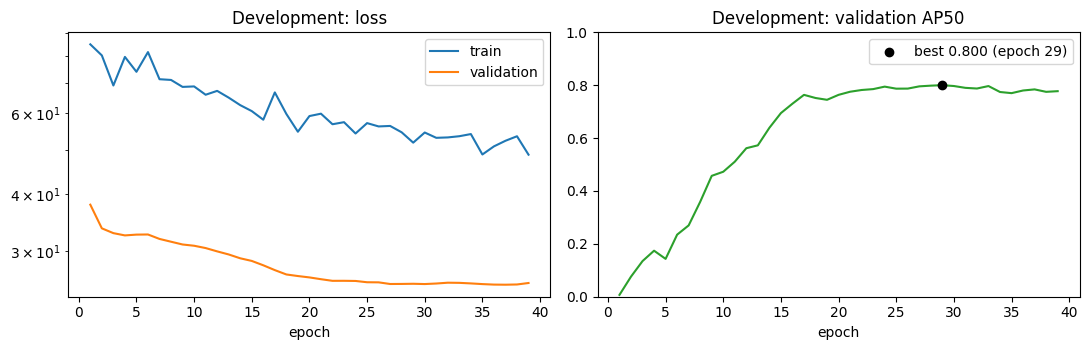

In [34]:
checkpoint = RUN.trained_checkpoint()
if checkpoint is None:
    checkpoint = develop(CONFIG, DATASET, RUN, DEVICE, search=SEARCH_CONFIGS)
else:
    CONFIG = TrainConfig.from_dict(torch.load(checkpoint, map_location="cpu", weights_only=True)["config"])
    print(f"Loaded finished training: {checkpoint}\nSettings: {CONFIG.to_dict()}")
if (RUN.report("search") / "search.csv").is_file():
    search_rows = list(csv.DictReader((RUN.report("search") / "search.csv").open()))
    for row in sorted(search_rows, key=lambda r: -float(r["best_map50"])):
        print(f"{row['trial']}: lr={row['lr']} weight_decay={row['weight_decay']} batch={row['batch']} "
              f"-> best AP50 {float(row['best_map50']):.4f} at epoch {row['best_epoch']}")
history = read_history(Path(checkpoint).parent / "history.csv")
plot_history(history, "Development")

## 8. Validation

Settings are chosen here and frozen for the test: the NMS IoU with the best AP50 and the operating confidence with
the best F1. Original and public validation images are reported separately to expose any domain gap (proposal
section 4.3).

REAL DATA - declared split: valid

YOLOv2 | valid | 92 images
AP50=0.8008  AP50:95=0.3766
Operating confidence=0.400  matching IoU=0.50
Precision=0.8227  Recall=0.7945  F1=0.8084  matched IoU=0.7521
TP=116  FP=25  FN=30
  drill: AP50=0.9596  AP50:95=0.5192  objects=52
  scissor: AP50=0.8010  AP50:95=0.3772  objects=47
  screwdriver: AP50=0.6417  AP50:95=0.2334  objects=47
  origin:original: 17 images, 42 objects, AP50=0.7727, AP50:95=0.3991
  origin:public: 75 images, 104 objects, AP50=0.8275, AP50:95=0.3812
NMS IoU=0.45
Parameters=37274760  checkpoint bytes=149204873
YOLOv2 NMS trials: 0.45: AP50=0.8008, 0.50: AP50=0.8002, 0.60: AP50=0.7969
Report metrics and figures: /content/drive/MyDrive/EE3703_yolov2_runs/finegrid4_20261104_0934/report/validation
NMS trials: {0.45: 0.8008, 0.5: 0.8002, 0.6: 0.7969}
Confidence trials (F1): {0.2: 0.7349, 0.3: 0.7717, 0.4: 0.8084}
Frozen settings: NMS IoU 0.45, operating confidence 0.4


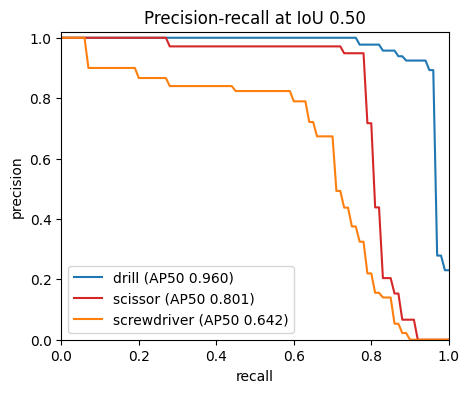

In [35]:
validation = RUN.result("validation")
if validation is None:
    validation = validate(checkpoint, DATASET, RUN, DEVICE, batch=CONFIG.batch)
else:
    print("Loaded finished validation:\n" + (RUN.report("validation") / "metrics.txt").read_text())
protocol = load_json(RUN.protocol_path)
settings = protocol["models"][MODEL_NAME]
print("NMS trials:", {row["nms_iou"]: round(row["map50"], 4) for row in protocol["nms_trials"][MODEL_NAME]})
print("Confidence trials (F1):", {row["confidence"]: round(row["micro_f1"], 4) for row in settings["confidence_trials"]})
print(f"Frozen settings: NMS IoU {settings['nms']['final_nms_iou']}, operating confidence {settings['operating_confidence']}")
plot_pr_curves(validation)

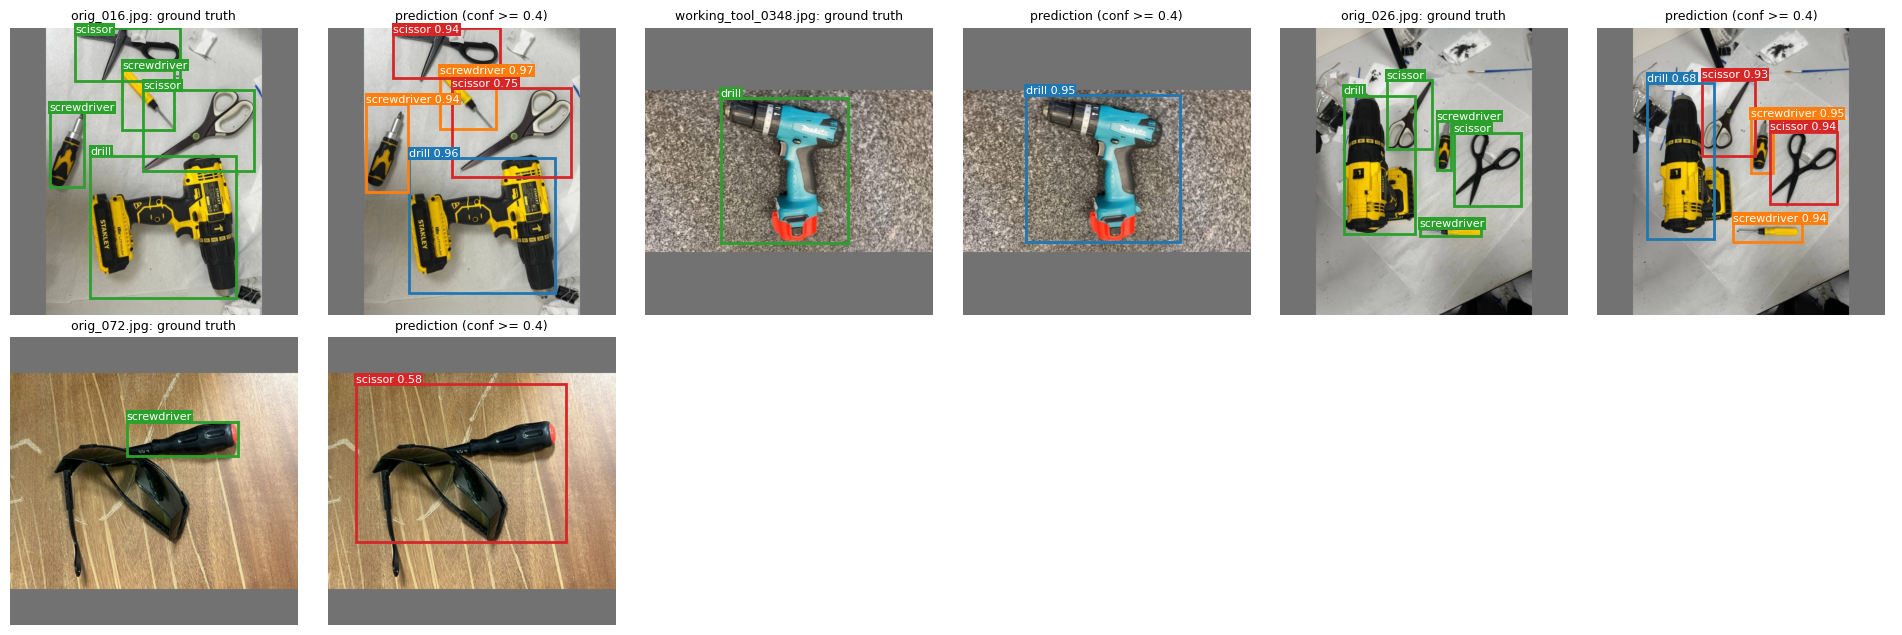

In [36]:
detector = YOLOv2Detector.from_checkpoint(checkpoint, DEVICE, protocol)
valid_truth = load_ground_truth(DATASET, "valid")
examples = pick_examples(validation)
shown = examples["success"][:2] + examples["missed_object"] + examples["background_or_low_overlap"]
if shown:
    show_predictions(detector, DATASET, "valid", valid_truth, shown)

## 9. Final test

Retrains from scratch on train + validation (450 images) for the development run's best epoch count, with every
setting frozen, then evaluates **once** on the 50 original test photos and measures inference speed (batch 1,
including preprocessing, decoding and NMS).

In [37]:
test = RUN.result("test")
if test is None and RUN_FINAL_TEST:
    test = final_test(RUN, DATASET, DEVICE)
elif test is not None:
    print("Loaded the finished test (it is never repeated):\n" + (RUN.report("test") / "metrics.txt").read_text())
if test is not None:
    timing = test["model_metadata"]["benchmark"]
    size = test["model_metadata"]["model_size"]
    print(f"Speed: {timing['mean_latency_ms']:.1f} ms/image ({timing['sequential_fps']:.1f} FPS) on {timing['device']}")
    print(f"Model: {size['parameter_count']:,} parameters, checkpoint {size['checkpoint_file_bytes'] / 1e6:.1f} MB")
    plot_pr_curves(test)
else:
    print("Final test not run. Set RUN_FINAL_TEST = True once every setting is fixed on validation.")

Final test not run. Set RUN_FINAL_TEST = True once every setting is fixed on validation.


## 10. Error analysis

Error types at the operating confidence, on the test split if it has been run, otherwise on validation. Categories
describe each mistake; they are not proven causes.

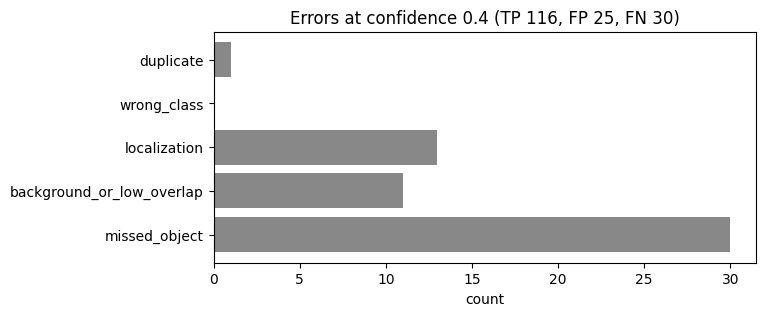

missed object


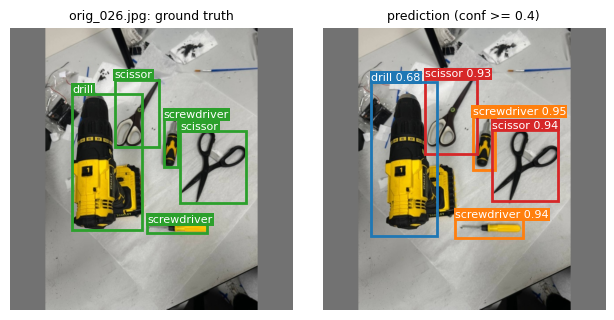

background or low overlap


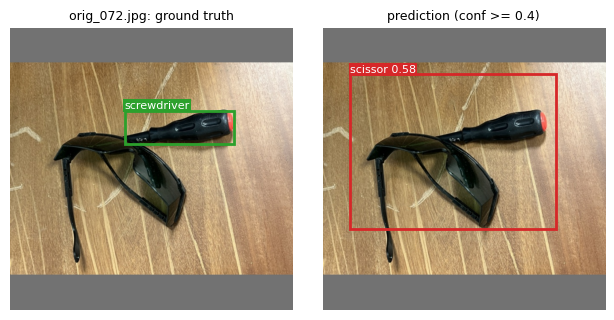

localization


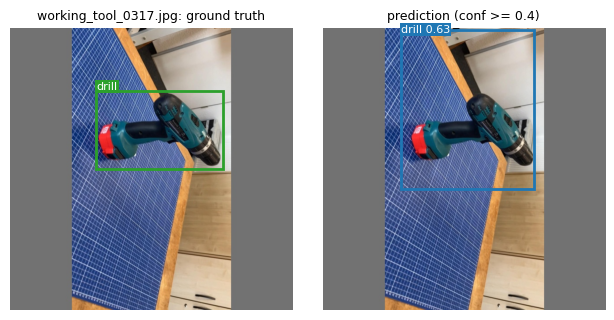

In [38]:
analysed, analysed_split = (test, "test") if test else (validation, "valid")
counts = plot_error_breakdown(analysed)
if test:
    detector = YOLOv2Detector.from_checkpoint(RUN.final_checkpoint(), DEVICE, protocol)
truth = load_ground_truth(DATASET, analysed_split, allow_test=analysed_split == "test")
examples = pick_examples(analysed)
for kind, ids in examples.items():
    if ids and kind != "success":
        print(kind.replace("_", " "))
        show_predictions(detector, DATASET, analysed_split, truth, ids)

## 11. Inference on photos

`predict_image` takes a photo of any size, letterboxes it like the training data, detects and maps the boxes back to
the photo's pixels. This is the same call the browser demo uses.

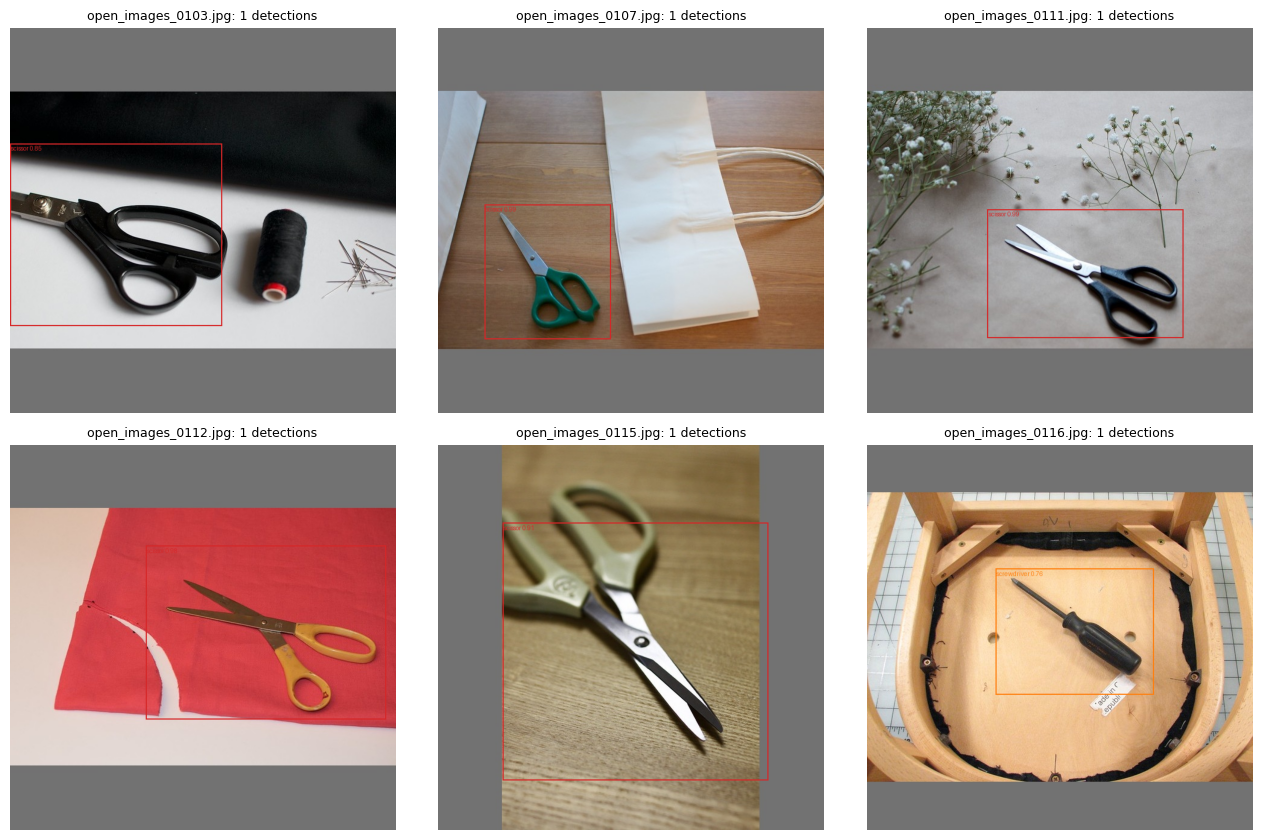

In [39]:
split = "test" if test else "valid"
folder = DATASET / split / "images"
photos = sorted(folder.iterdir())[:6]
_, axes = plt.subplots(2, 3, figsize=(13, 8.5))
for axis, path in zip(axes.flat, photos):
    image = Image.open(path).convert("RGB")
    found = detector.predict_image(image)
    axis.imshow(draw_detections(image, found))
    axis.set_title(f"{path.name}: {len(found)} detections", fontsize=9)
    axis.axis("off")
plt.tight_layout()
plt.show()
if test is not None:  # every test photo with its detections, for the demo video
    saved = RUN.root / "test_predictions"
    saved.mkdir(exist_ok=True)
    for path in sorted(folder.iterdir()):
        image = Image.open(path).convert("RGB")
        draw_detections(image, detector.predict_image(image)).save(saved / path.name, quality=92)
    print(f"Saved {len(list(saved.iterdir()))} annotated test photos to {saved}")
# Your own photo: detector.predict_image(Image.open("photo.jpg").convert("RGB"))

## 12. Results and conclusions

Achieved AP50 against the targets in the proposal (sections 1.3 and 1.4).

In [40]:
final = test or validation
targets = {"overall": 0.70, "drill": 0.75, "scissor": 0.65, "screwdriver": 0.70}
f3 = lambda value, width: f"{'n/a':>{width}}" if value is None else f"{value:>{width}.3f}"
print(f"{'split: ' + ('test (50 originals)' if test else 'validation (not the final result)'):<40}")
print(f"{'':<14}{'AP50':>8}{'target':>9}{'AP50:95':>10}{'precision':>11}{'recall':>8}{'F1':>7}")
print(f"{'overall':<14}{f3(final['map50'], 8)}{targets['overall']:>9.2f}{f3(final['map_iou_average'], 10)}"
      f"{f3(final['precision_micro'], 11)}{f3(final['recall_micro'], 8)}{f3(final['f1_micro'], 7)}")
for row in final["per_class"]:
    print(f"{row['class_name']:<14}{f3(row['ap50'], 8)}{targets[row['class_name']]:>9.2f}{f3(row['ap_iou_average'], 10)}"
          f"{f3(row['precision'], 11)}{f3(row['recall'], 8)}{f3(row['f1'], 7)}")
for name, subset in final["subsets"].items():
    print(f"{name:<22} AP50 {f3(subset['map50'], 0).strip()} ({subset['image_count']} images)")
print(f"\nRun folder: {RUN.root.resolve()}")

split: validation (not the final result)
                  AP50   target   AP50:95  precision  recall     F1
overall          0.801     0.70     0.377      0.823   0.795  0.808
drill            0.960     0.75     0.519      0.923   0.923  0.923
scissor          0.801     0.65     0.377      0.841   0.787  0.813
screwdriver      0.642     0.70     0.233      0.689   0.660  0.674
origin:original        AP50 0.773 (17 images)
origin:public          AP50 0.827 (75 images)

Run folder: /content/drive/MyDrive/EE3703_yolov2_runs/finegrid4_20261104_0934


### Conclusions

*To be written from the results above:* how close each class came to its target and why; what the error analysis
shows (for example missed thin scissors versus background detections); whether original photos score below public
ones; and what would improve the detector next.